# streamspraydf + streamTrack stress test on galstreams streams

Tests the new `streamTrack` implementation on **all decent galstreams
streams** (filtered: has pm, has D, width_phi2 ≥ 0.05°, length ≥ 3°).
For each stream a 5-Gyr `fardal15spraydf` is built in `MWPotential2014`,
starting at 4×10⁴ M☉ progenitor mass. Target width is
`0.3 × galstreams.width_phi2` (galstreams widths are STREAMFINDER search
half-widths, ~3–5× the intrinsic Gaussian σ). The progenitor mass is
rescaled with σ ∝ M^(1/3) until the width matches.

**Compute is done out-of-band** by `run_all_streams.py` (parallel across
cores). This notebook just displays the results.

In [1]:
# Loads precomputed results. Run run_all_streams.py first to fill
# /tmp/galstream_stress_{figs,results}/.
import glob, os, pickle
from IPython.display import Image, display

FIGS = os.environ.get("GALSTREAM_FIGDIR", "/tmp/galstream_stress_figs")
RES = os.environ.get("GALSTREAM_RESULTS", "/tmp/galstream_stress_results")

def load_result(name):
    path = f"{RES}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

def show_stream(name):
    r = load_result(name)
    if r is None:
        print(f"{name}: no pickled result found")
    else:
        print(f"{name}:  galstreams width = {r['galstreams_width']:.3f}°, "
              f"target = {r['target_width']:.3f}°, "
              f"baseline w = {r['baseline_width']:.3f}°, "
              f"rescaled w = {r['final_width']:.3f}°, "
              f"M = {r['final_mass']:.2e} M_sun")
    fig = f"{FIGS}/{name}.png"
    if os.path.exists(fig):
        display(Image(fig))
    else:
        print(f"  (figure {fig} missing)")


## Summary table

Table of every stream's galstreams width, scaled target, baseline and rescaled widths, and fitted mass.

In [2]:
names = sorted(
    [os.path.basename(p)[:-4] for p in glob.glob(f"{RES}/*.pkl")],
    key=lambda n: -load_result(n)['galstreams_width'] * 0 + (
        0 if n == 'GD-1-I21' else 1
    )
)
# Keep GD-1 first, rest by galstreams width descending
if 'GD-1-I21' in names:
    names.remove('GD-1-I21')
names = ['GD-1-I21'] + sorted(names, key=lambda n: -load_result(n)['galstreams_width'])

print(f"{'stream':<22}  {'gs w':>6}  {'targ':>6}  {'Mfit w':>7}  "
      f"{'Mfit [M☉]':>9}  {'L_tgt':>6}  {'L_fit':>6}  {'T_fit [Gyr]':>11}")
for n in names:
    r = load_result(n)
    if r is None: continue
    L_tgt = r.get('target_length', float('nan'))
    L_fit = r.get('final_length', float('nan'))
    T_fit = r.get('final_tdisrupt_gyr', float('nan'))
    print(f"{r['name']:<22}  {r['galstreams_width']:>5.2f}°  "
          f"{r['target_width']:>5.2f}°  {r['final_width']:>6.2f}°  "
          f"{r['final_mass']:>9.2e}  {L_tgt:>5.0f}°  {L_fit:>5.0f}°  "
          f"{T_fit:>10.2f}")


stream                    gs w    targ   Mfit w  Mfit [M☉]   L_tgt   L_fit  T_fit [Gyr]
GD-1-I21                 0.65°   0.20°    0.22°   4.92e+04    103°    117°        2.16
LMS1-Y20                 8.66°   2.60°    2.32°   1.13e+09    179°    674°        0.68
Cetus-Palca-T21          4.40°   1.32°    1.41°   4.75e+07    101°    624°        2.27
New-2-I24                4.39°   1.32°    1.46°   2.84e+07     64°    154°        0.30
Aquarius-W11             3.78°   1.13°    1.14°   8.01e+05     12°     72°        0.30
New-5-I24                3.76°   1.13°    1.16°   3.39e+03     99°    121°        0.74
New-6-I24                3.74°   1.12°    1.34°   1.63e+04     80°     88°        0.30
New-3-I24                3.36°   1.01°    1.84°   3.27e+07     71°    224°        0.30
Cetus-New-Y21            3.16°   0.95°    1.15°   3.08e+07     68°     60°        0.38
New-15-I24               3.15°   0.94°    1.57°   9.05e+04     20°    124°        0.30
C-9-I24                  2.74°   0.82°    

## Stream 0: `GD-1-I21` (well-studied reference)

GD-1-I21:  galstreams width = 0.652°, target = 0.196°, baseline w = 0.196°, rescaled w = 0.218°, M = 4.92e+04 M_sun


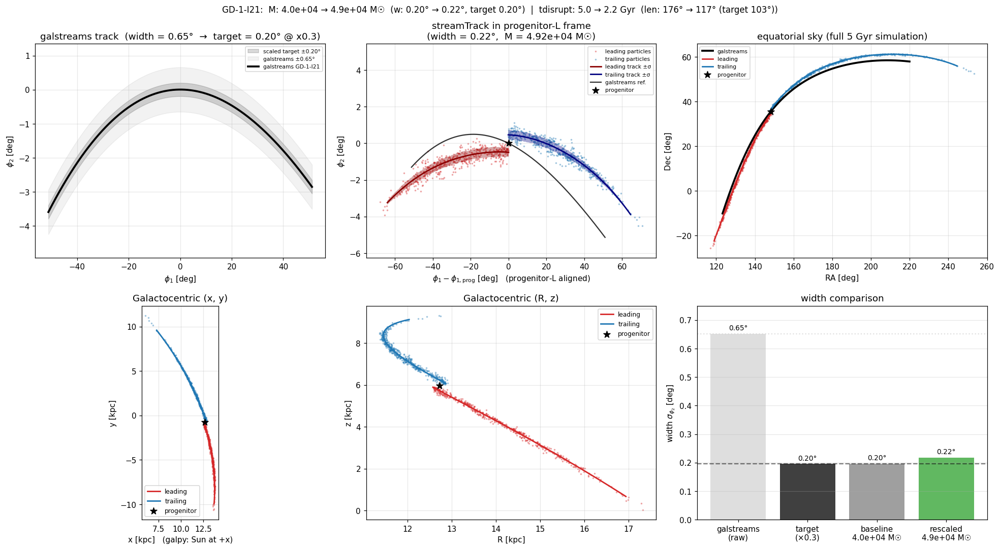

In [3]:
show_stream('GD-1-I21')

## Stream 1: `LMS1-Y20`

LMS1-Y20:  galstreams width = 8.664°, target = 2.599°, baseline w = 0.131°, rescaled w = 2.316°, M = 1.13e+09 M_sun


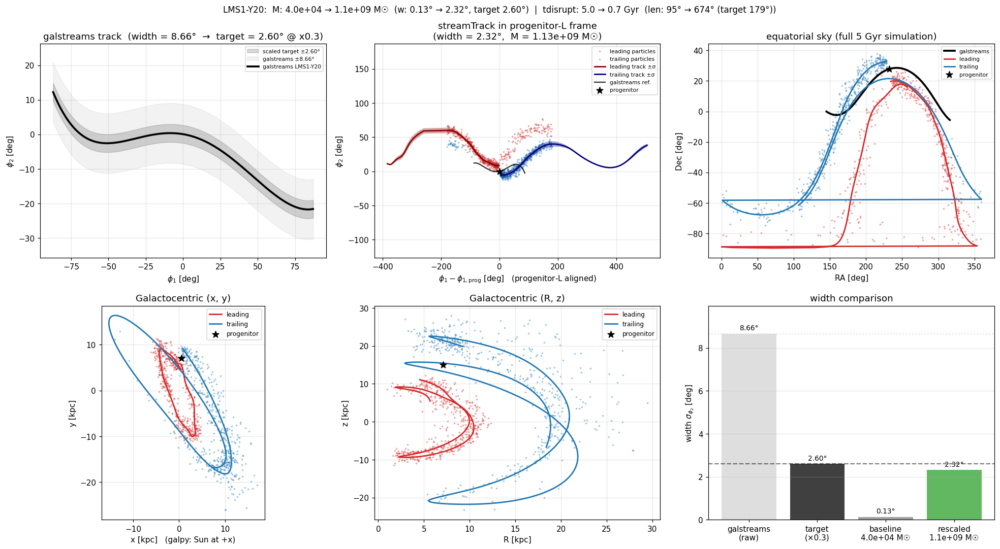

In [4]:
show_stream('LMS1-Y20')

## Stream 2: `NGC3201-P21`

NGC3201-P21:  galstreams width = 0.683°, target = 0.205°, baseline w = 0.995°, rescaled w = 0.240°, M = 1.00e+02 M_sun


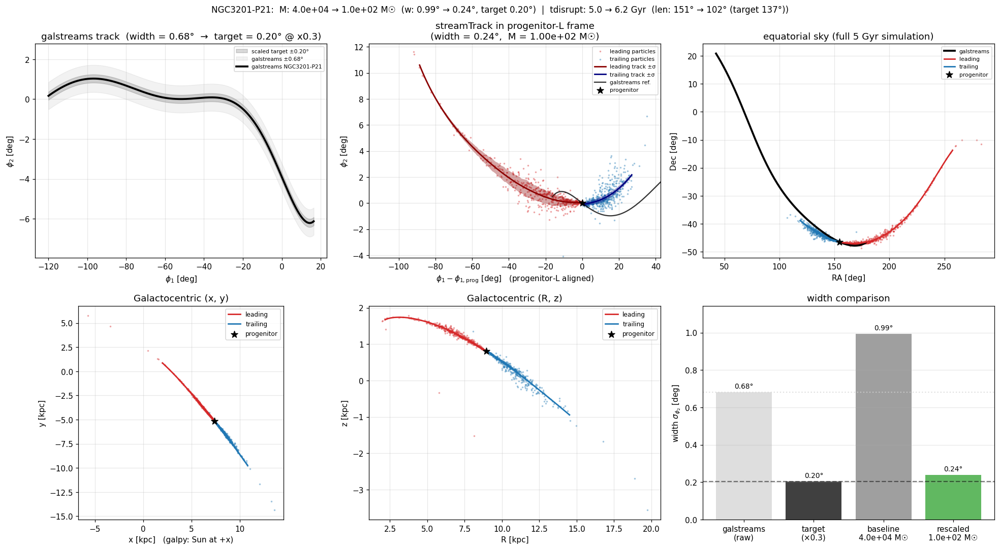

In [5]:
show_stream('NGC3201-P21')

## Stream 3: `M68-P19`

M68-P19:  galstreams width = 0.684°, target = 0.205°, baseline w = 0.322°, rescaled w = 0.174°, M = 5.84e+03 M_sun


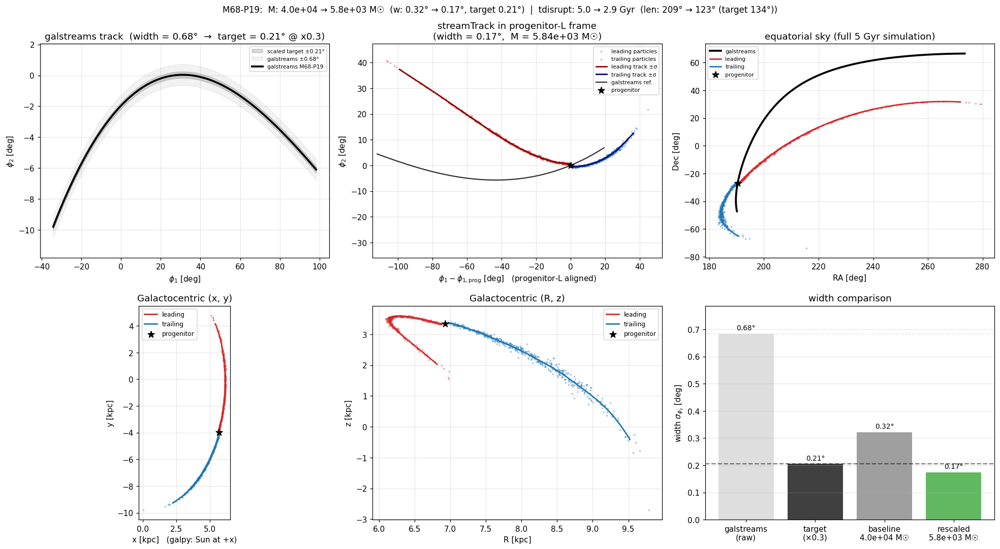

In [6]:
show_stream('M68-P19')

## Stream 4: `Cetus-Palca-T21`

Cetus-Palca-T21:  galstreams width = 4.402°, target = 1.321°, baseline w = 0.160°, rescaled w = 1.407°, M = 4.75e+07 M_sun


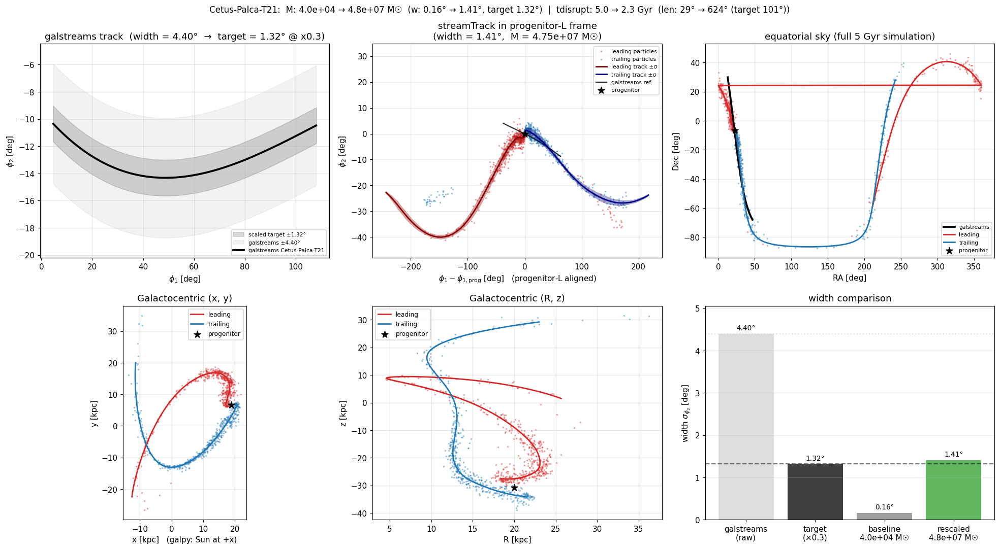

In [7]:
show_stream('Cetus-Palca-T21')

## Stream 5: `New-5-I24`

New-5-I24:  galstreams width = 3.760°, target = 1.128°, baseline w = 1.867°, rescaled w = 1.163°, M = 3.39e+03 M_sun


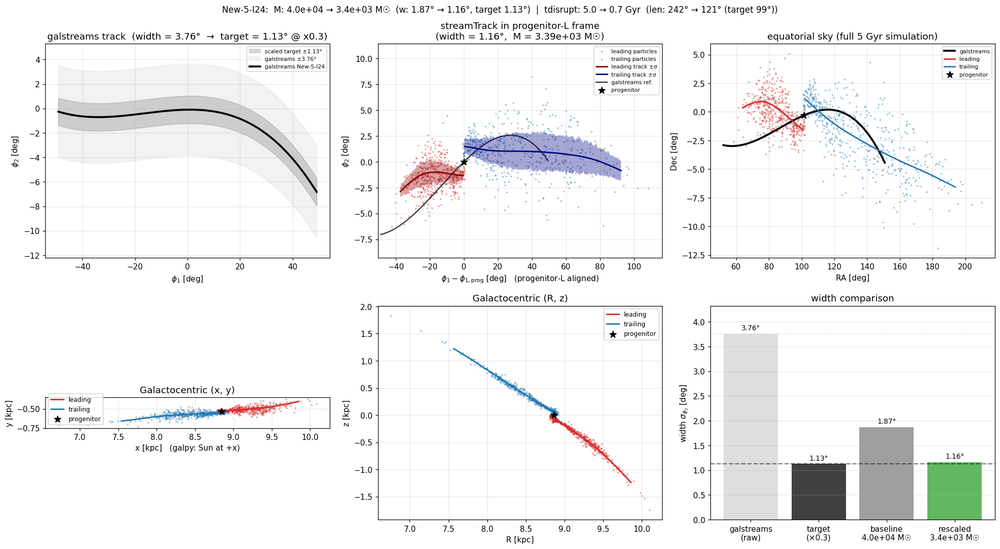

In [8]:
show_stream('New-5-I24')

## Stream 6: `New-6-I24`

New-6-I24:  galstreams width = 3.743°, target = 1.123°, baseline w = 0.498°, rescaled w = 1.337°, M = 1.63e+04 M_sun


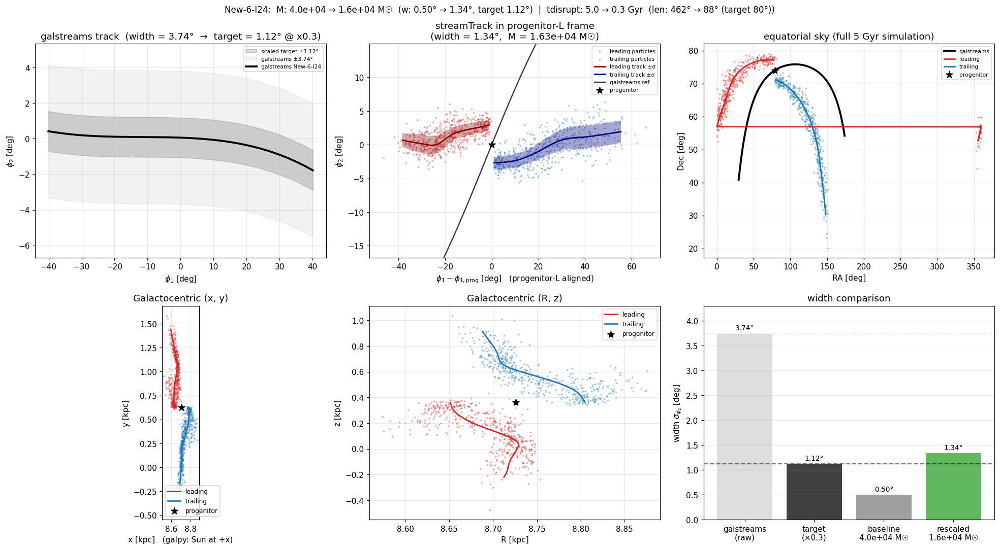

In [9]:
show_stream('New-6-I24')

## Stream 7: `New-3-I24`

New-3-I24:  galstreams width = 3.359°, target = 1.008°, baseline w = 0.246°, rescaled w = 1.843°, M = 3.27e+07 M_sun


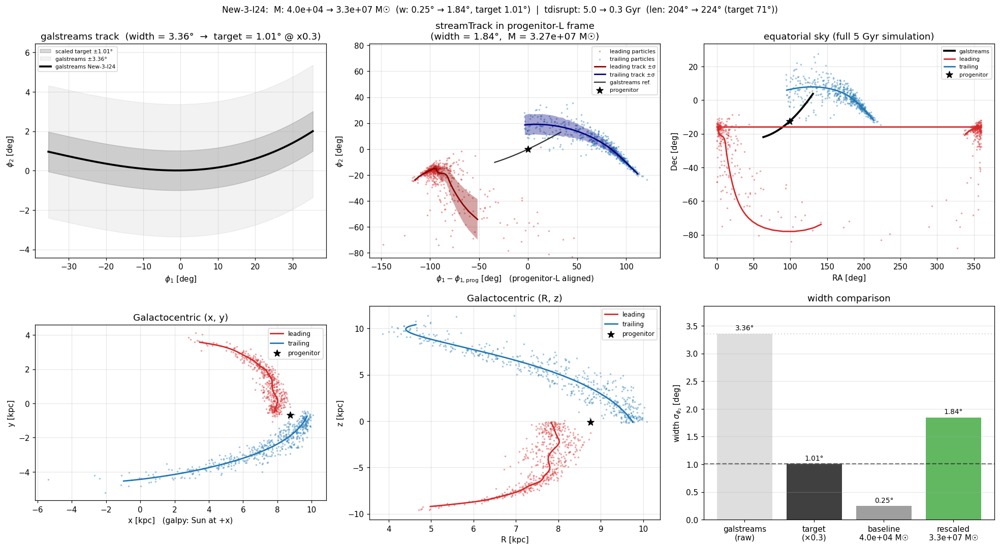

In [10]:
show_stream('New-3-I24')

## Stream 8: `Leiptr-I21`

Leiptr-I21:  galstreams width = 0.503°, target = 0.151°, baseline w = 0.170°, rescaled w = 0.170°, M = 1.49e+04 M_sun


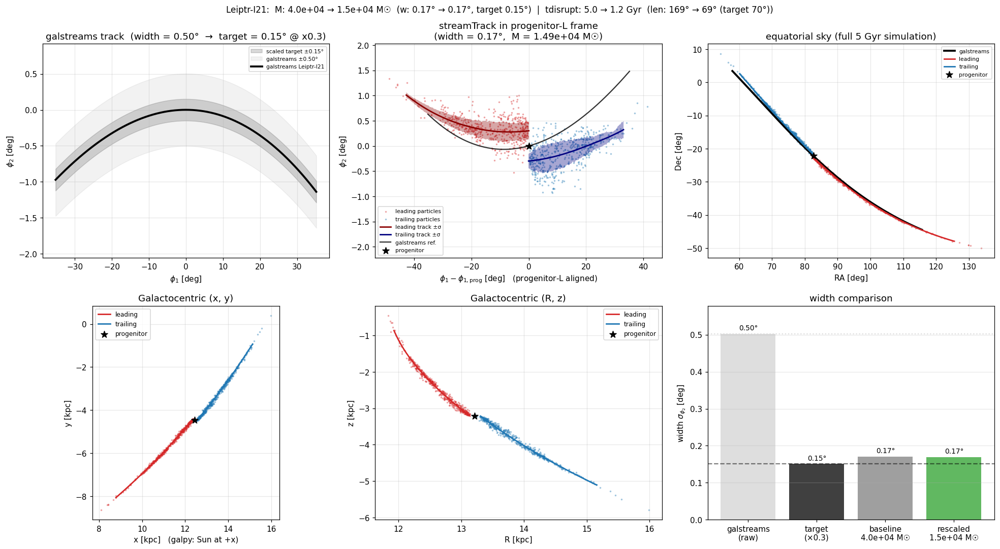

In [11]:
show_stream('Leiptr-I21')

## Stream 9: `Cetus-New-Y21`

Cetus-New-Y21:  galstreams width = 3.164°, target = 0.949°, baseline w = 0.096°, rescaled w = 1.151°, M = 3.08e+07 M_sun


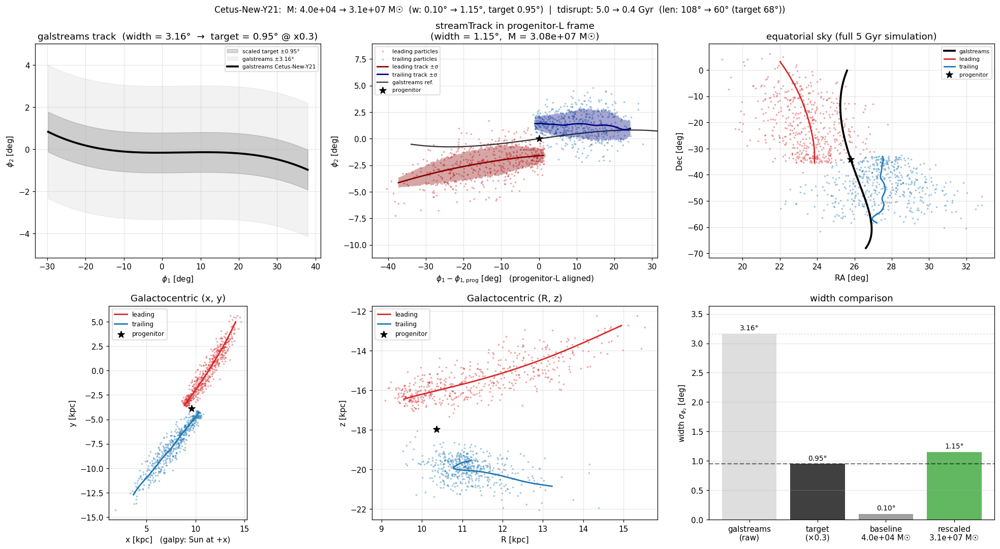

In [12]:
show_stream('Cetus-New-Y21')

## Stream 10: `New-2-I24`

New-2-I24:  galstreams width = 4.390°, target = 1.317°, baseline w = 0.208°, rescaled w = 1.458°, M = 2.84e+07 M_sun


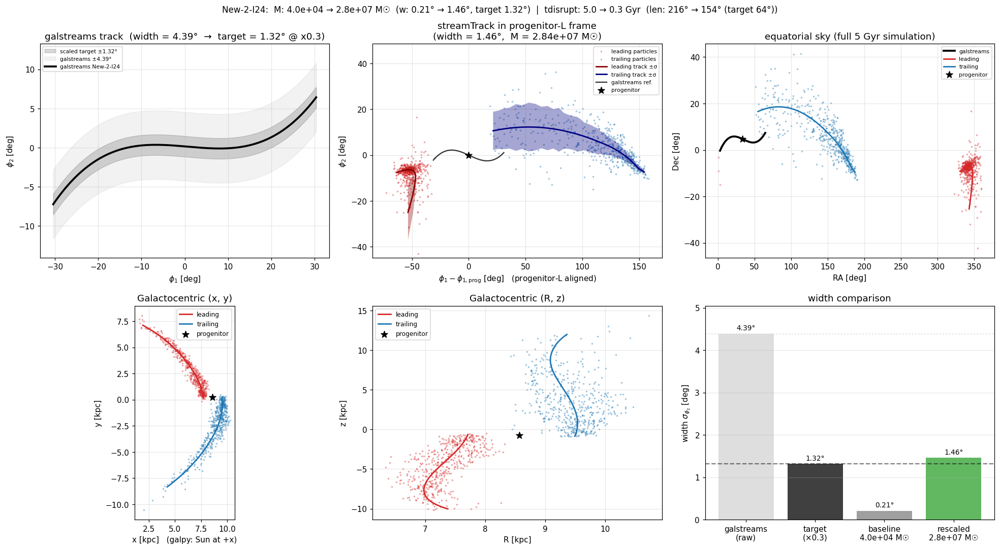

In [13]:
show_stream('New-2-I24')

## Stream 11: `Phlegethon-I21`

Phlegethon-I21:  galstreams width = 1.213°, target = 0.364°, baseline w = 0.665°, rescaled w = 0.365°, M = 9.49e+04 M_sun


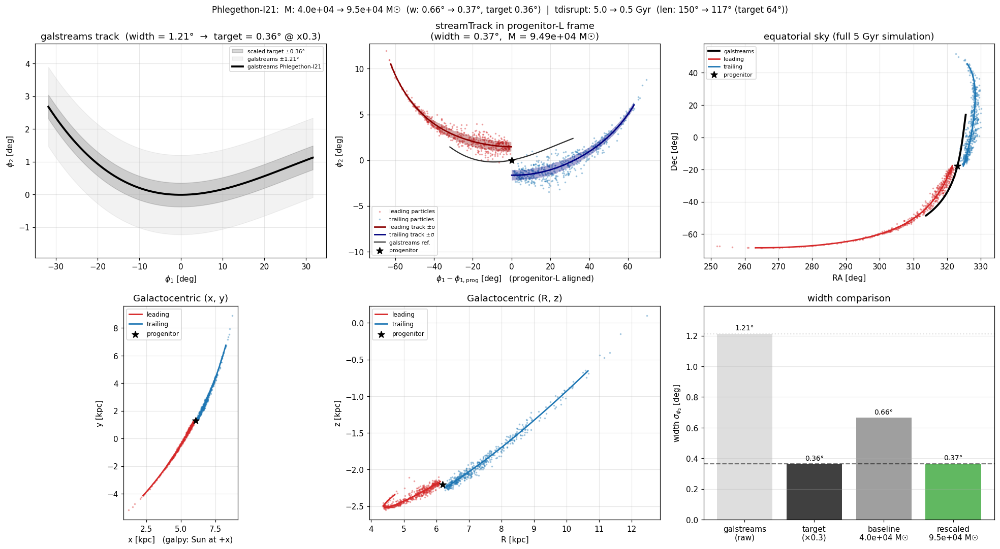

In [14]:
show_stream('Phlegethon-I21')

## Stream 12: `Hrid-I21`

Hrid-I21:  galstreams width = 0.872°, target = 0.261°, baseline w = 1.152°, rescaled w = 0.365°, M = 1.35e+02 M_sun


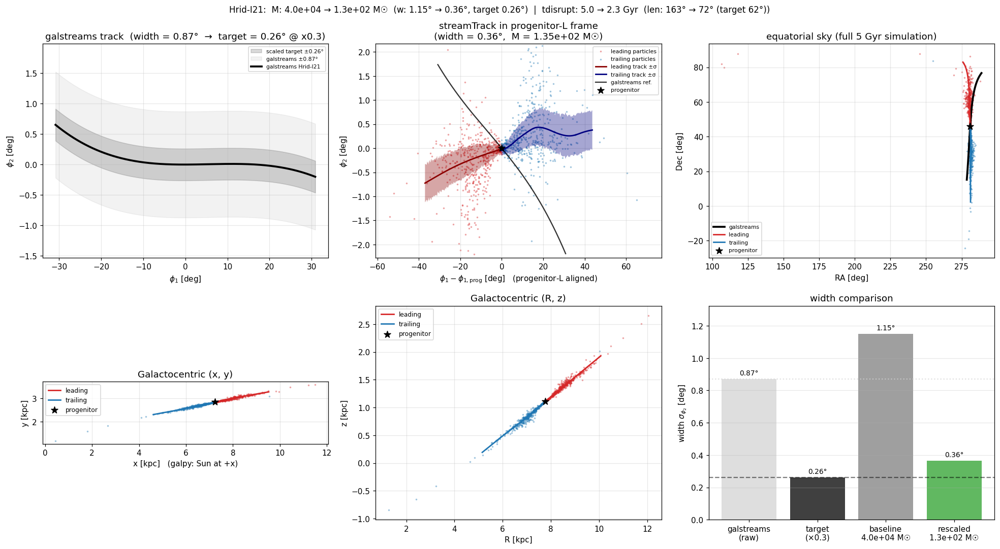

In [15]:
show_stream('Hrid-I21')

## Stream 13: `Ylgr-I21`

Ylgr-I21:  galstreams width = 0.905°, target = 0.272°, baseline w = 0.225°, rescaled w = 0.316°, M = 2.55e+05 M_sun


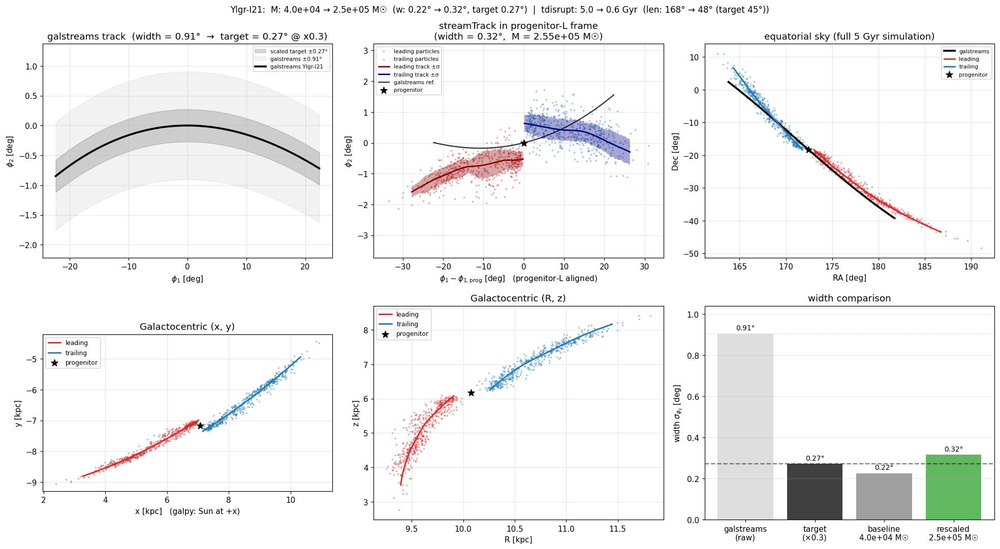

In [16]:
show_stream('Ylgr-I21')

## Stream 14: `M3-Y23`

M3-Y23:  galstreams width = 0.527°, target = 0.158°, baseline w = 0.434°, rescaled w = 0.149°, M = 1.42e+03 M_sun


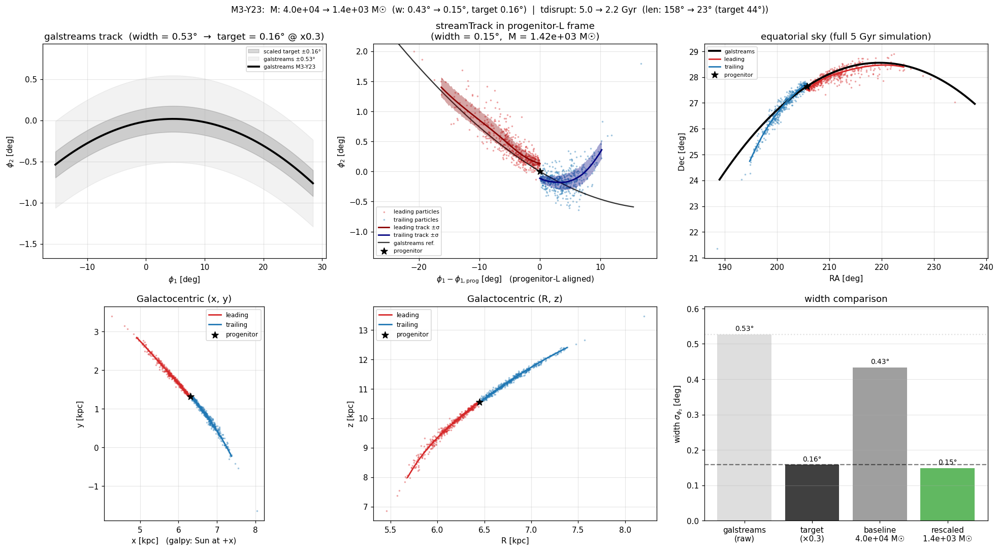

In [17]:
show_stream('M3-Y23')

## Stream 15: `OmegaCen-I21`

OmegaCen-I21:  galstreams width = 0.133°, target = 0.040°, baseline w = 0.160°, rescaled w = 0.387°, M = 1.00e+02 M_sun


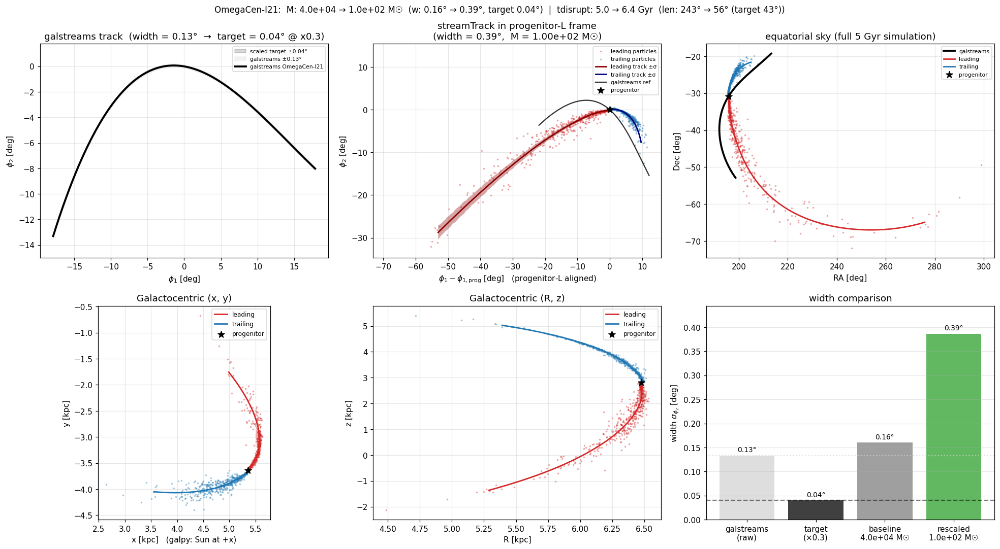

In [18]:
show_stream('OmegaCen-I21')

## Stream 16: `C-24-I24`

C-24-I24:  galstreams width = 0.808°, target = 0.243°, baseline w = 1.201°, rescaled w = 0.343°, M = 1.00e+02 M_sun


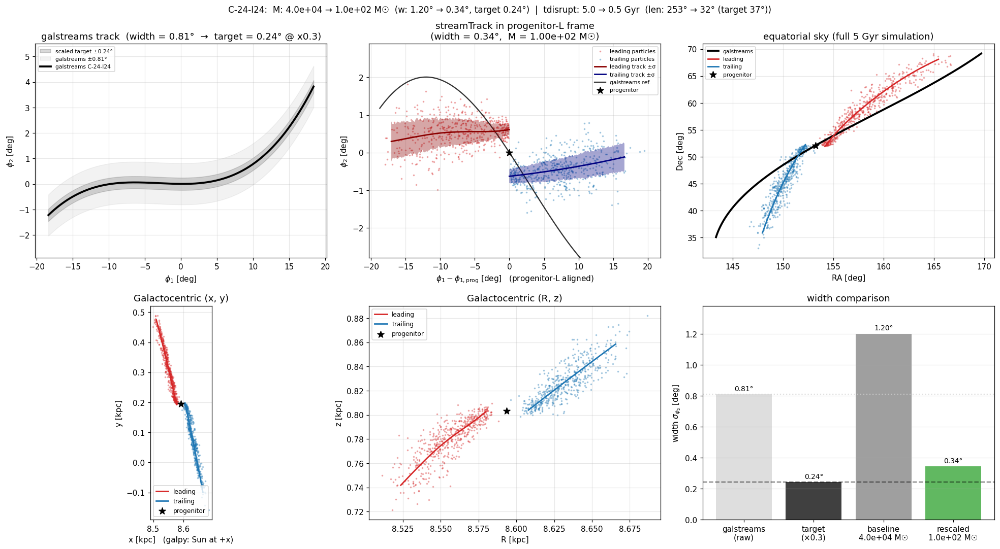

In [19]:
show_stream('C-24-I24')

## Stream 17: `C-11-I24`

C-11-I24:  galstreams width = 2.199°, target = 0.660°, baseline w = 0.397°, rescaled w = 0.732°, M = 4.77e+03 M_sun


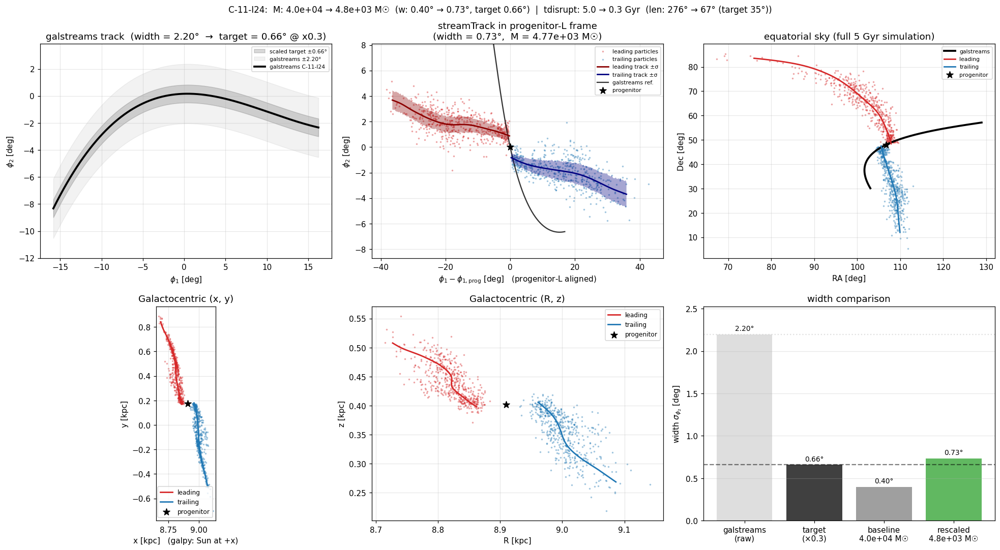

In [20]:
show_stream('C-11-I24')

## Stream 18: `Svol-I21`

Svol-I21:  galstreams width = 1.049°, target = 0.315°, baseline w = 0.468°, rescaled w = 0.321°, M = 1.22e+05 M_sun


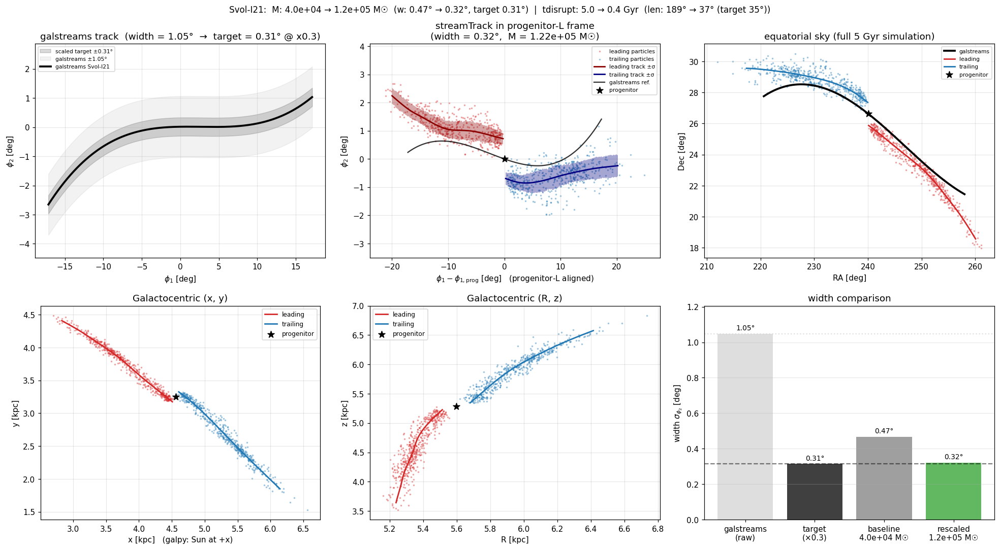

In [21]:
show_stream('Svol-I21')

## Stream 19: `Gaia-1-I21`

Gaia-1-I21:  galstreams width = 0.384°, target = 0.115°, baseline w = 0.178°, rescaled w = 0.078°, M = 7.95e+02 M_sun


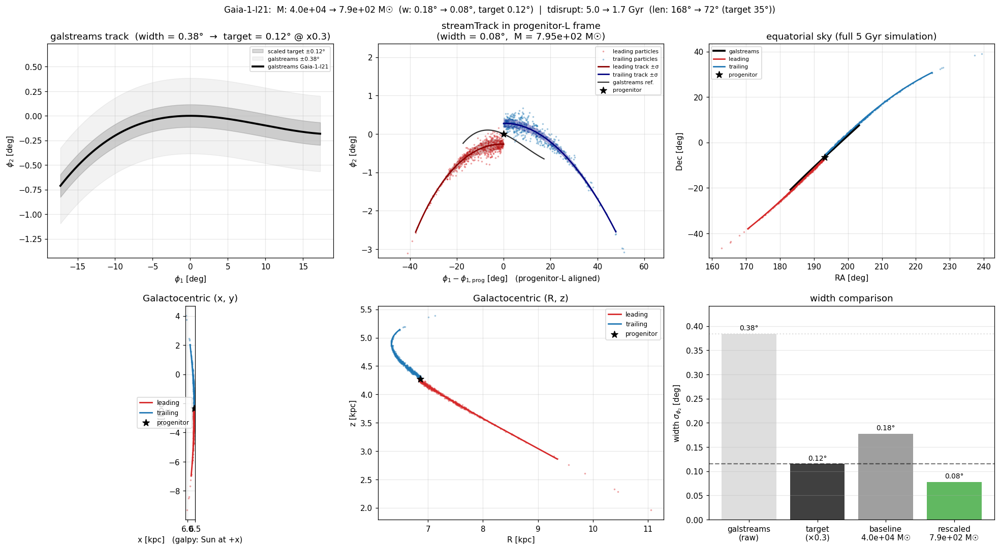

In [22]:
show_stream('Gaia-1-I21')

## Stream 20: `Slidr-I21`

Slidr-I21:  galstreams width = 1.715°, target = 0.514°, baseline w = 0.311°, rescaled w = 0.510°, M = 1.95e+05 M_sun


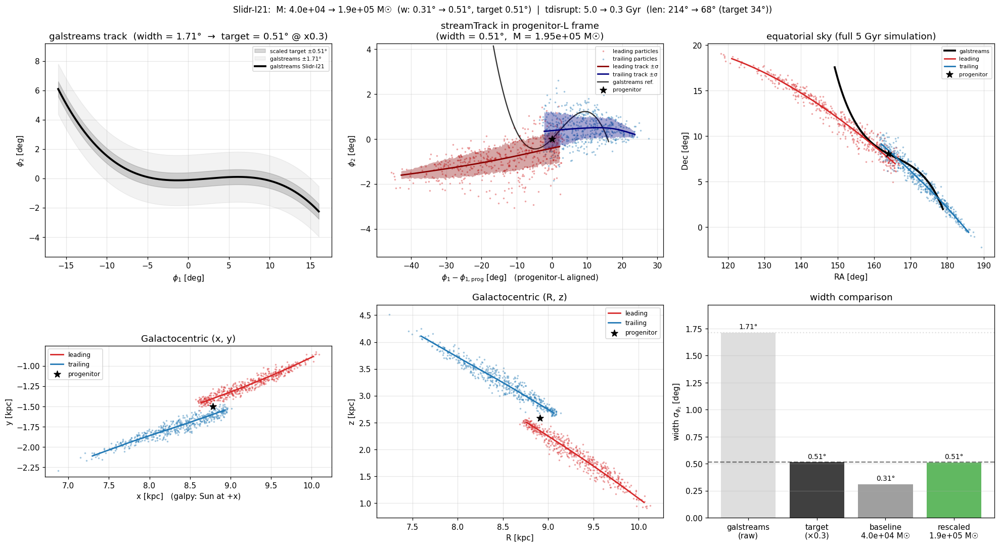

In [23]:
show_stream('Slidr-I21')

## Stream 21: `C-9-I24`

C-9-I24:  galstreams width = 2.736°, target = 0.821°, baseline w = 0.649°, rescaled w = 0.819°, M = 6.49e+03 M_sun


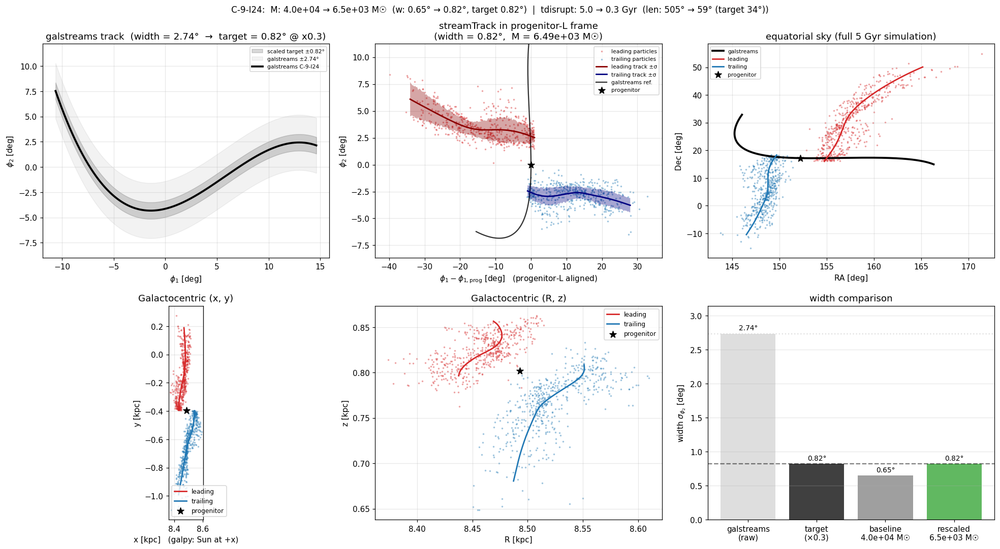

In [24]:
show_stream('C-9-I24')

## Stream 22: `NGC5466-J21`

NGC5466-J21:  galstreams width = 1.195°, target = 0.359°, baseline w = 0.109°, rescaled w = 0.423°, M = 4.68e+06 M_sun


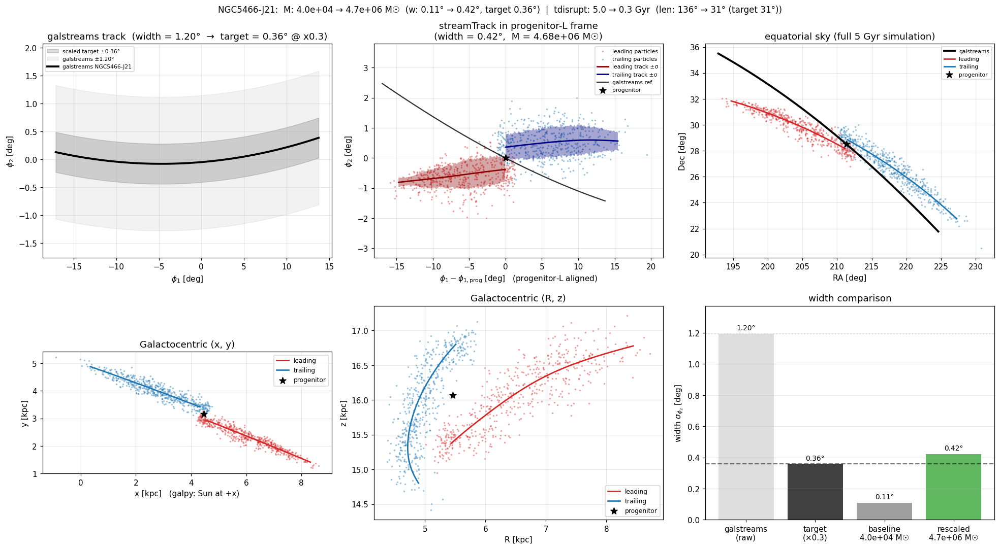

In [25]:
show_stream('NGC5466-J21')

## Stream 23: `Jet-F22`

Jet-F22:  galstreams width = 0.232°, target = 0.070°, baseline w = 0.143°, rescaled w = 0.049°, M = 1.18e+03 M_sun


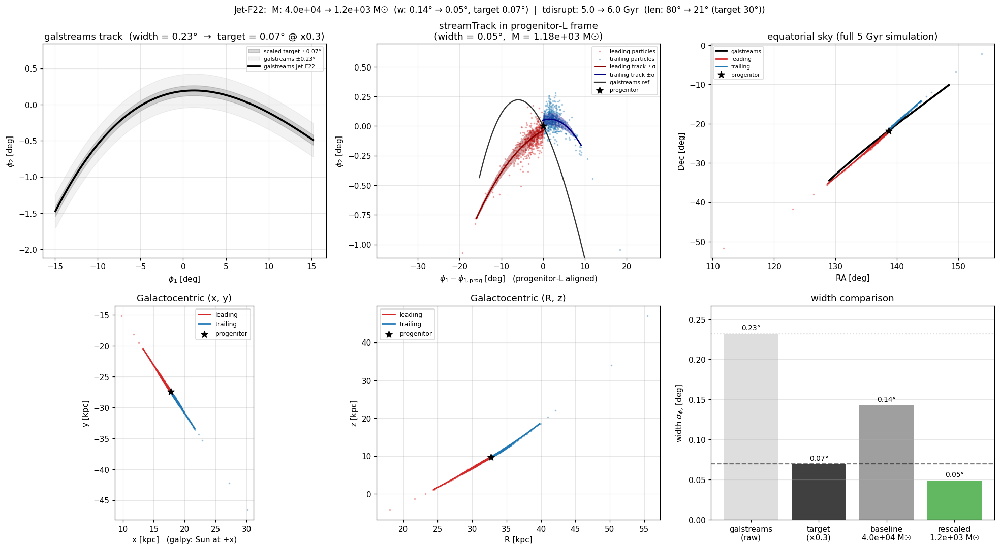

In [26]:
show_stream('Jet-F22')

## Stream 24: `New-23-I24`

New-23-I24:  galstreams width = 0.757°, target = 0.227°, baseline w = 1.336°, rescaled w = 0.427°, M = 1.00e+02 M_sun


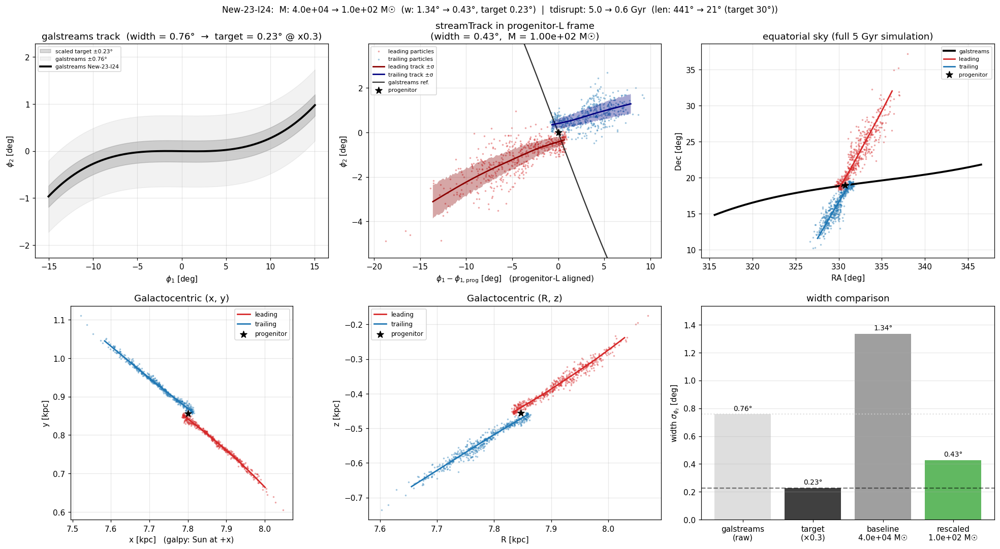

In [27]:
show_stream('New-23-I24')

## Stream 25: `C-25-I24`

C-25-I24:  galstreams width = 2.650°, target = 0.795°, baseline w = 1.764°, rescaled w = 0.784°, M = 7.51e+03 M_sun


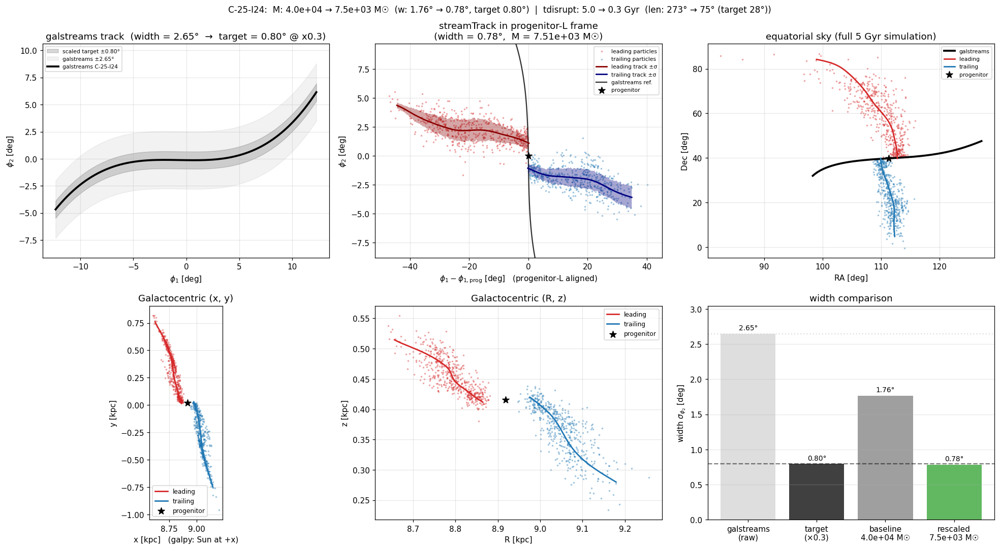

In [28]:
show_stream('C-25-I24')

## Stream 26: `C-12-I24`

C-12-I24:  galstreams width = 0.796°, target = 0.239°, baseline w = 4.020°, rescaled w = 0.863°, M = 1.00e+02 M_sun


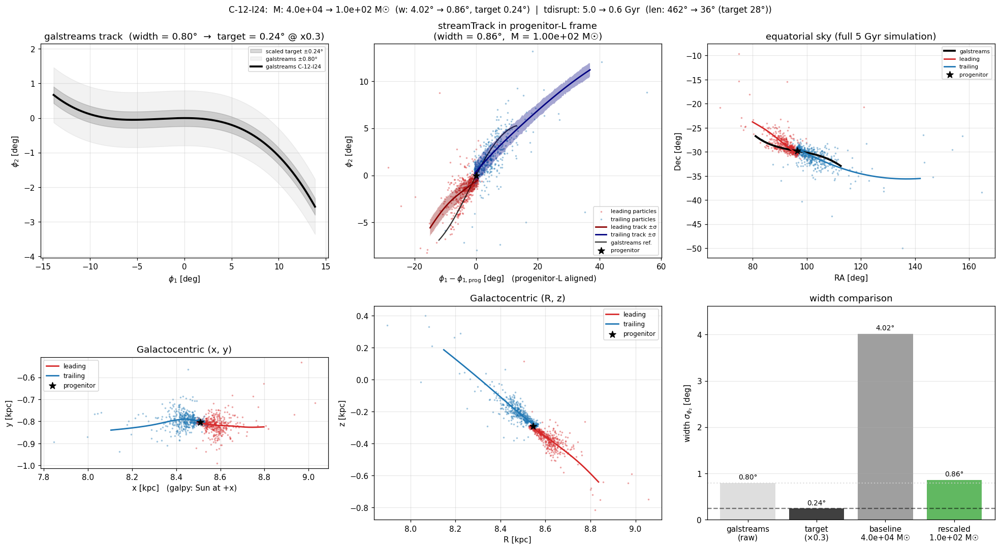

In [29]:
show_stream('C-12-I24')

## Stream 27: `Sylgr-I21`

Sylgr-I21:  galstreams width = 1.161°, target = 0.348°, baseline w = 0.257°, rescaled w = 0.293°, M = 1.48e+04 M_sun


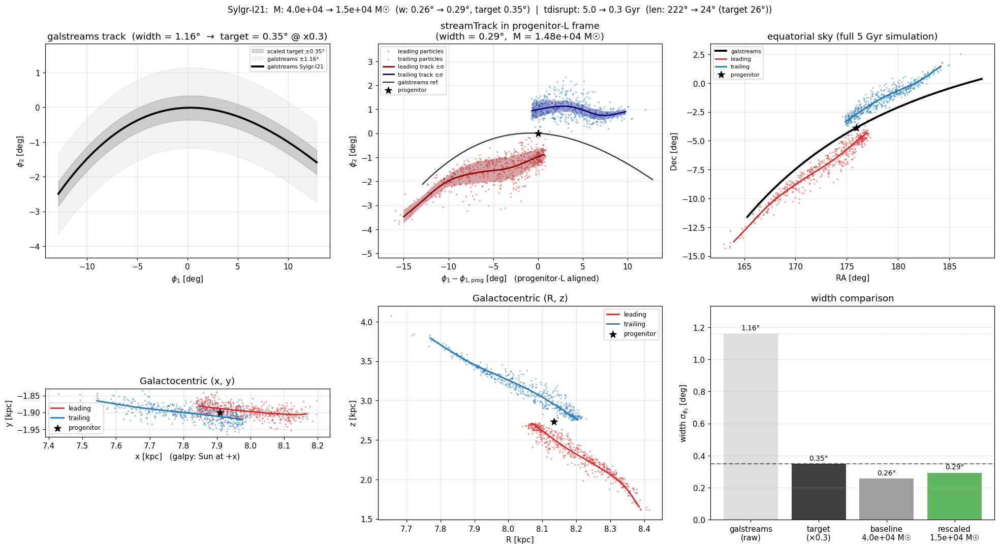

In [30]:
show_stream('Sylgr-I21')

## Stream 28: `New-10-I24`

New-10-I24:  galstreams width = 1.153°, target = 0.346°, baseline w = 0.726°, rescaled w = 0.395°, M = 4.69e+02 M_sun


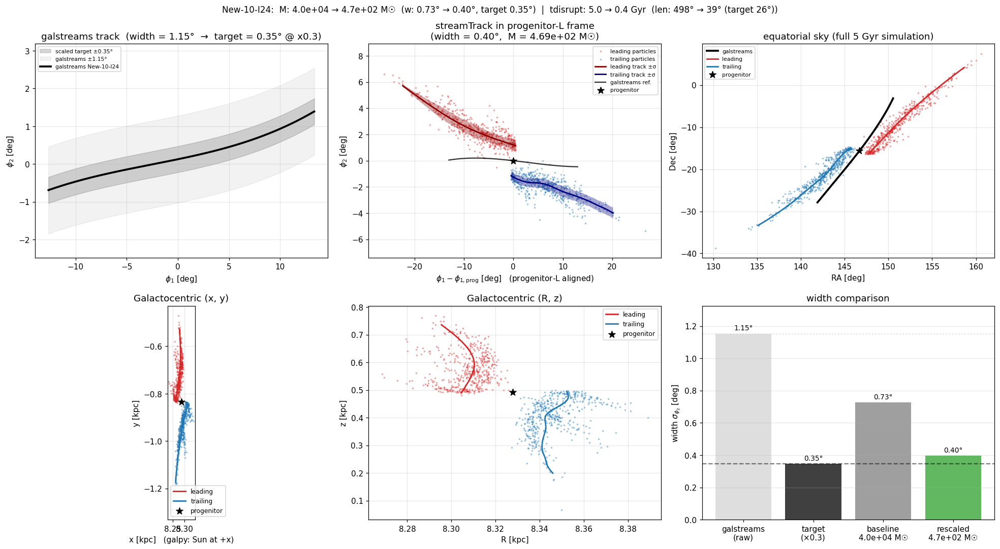

In [31]:
show_stream('New-10-I24')

## Stream 29: `New-7-I24`

New-7-I24:  galstreams width = 1.018°, target = 0.305°, baseline w = 1.083°, rescaled w = 0.277°, M = 2.04e+02 M_sun


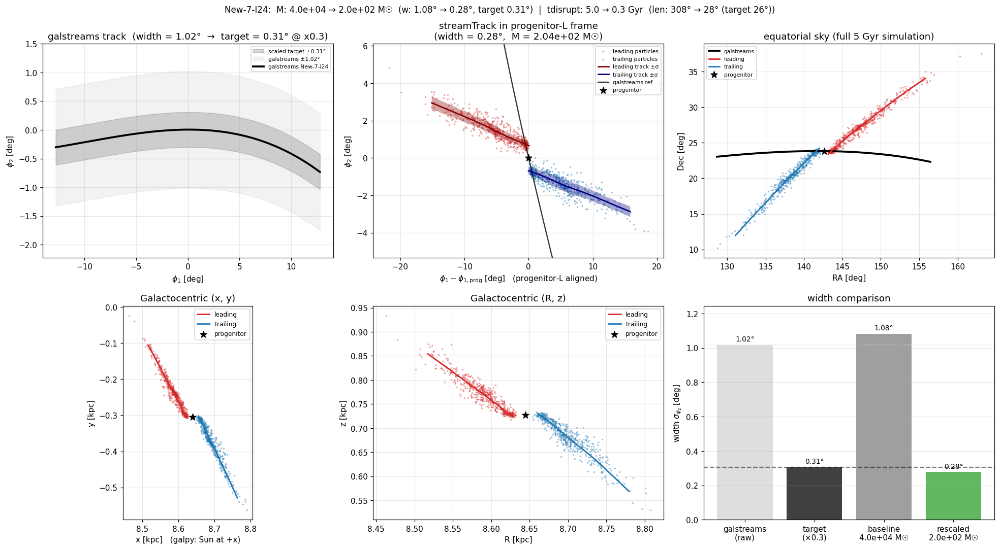

In [32]:
show_stream('New-7-I24')

## Stream 30: `C-7-I21`

C-7-I21:  galstreams width = 0.735°, target = 0.220°, baseline w = 0.662°, rescaled w = 0.199°, M = 3.85e+04 M_sun


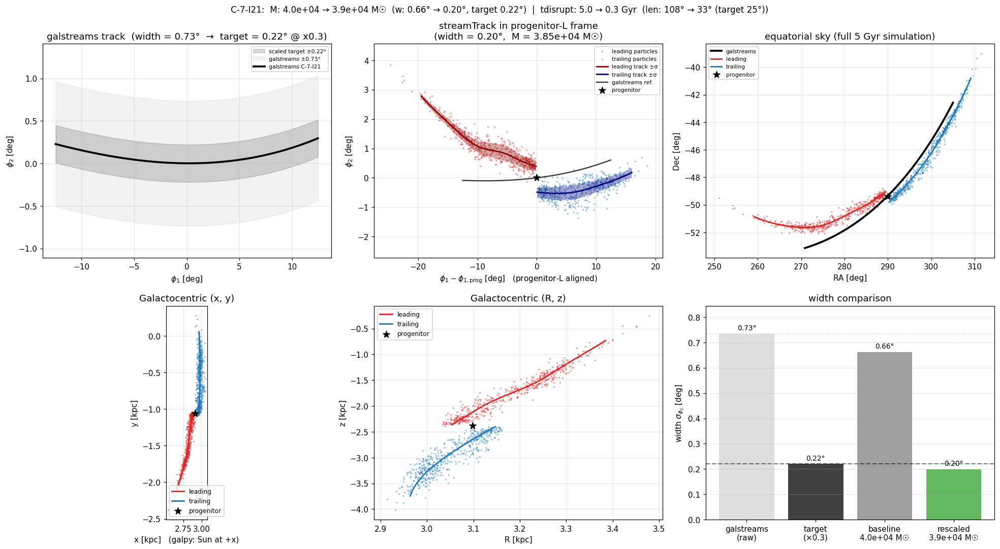

In [33]:
show_stream('C-7-I21')

## Stream 31: `C-13-I24`

C-13-I24:  galstreams width = 0.602°, target = 0.181°, baseline w = 0.246°, rescaled w = 0.182°, M = 1.00e+02 M_sun


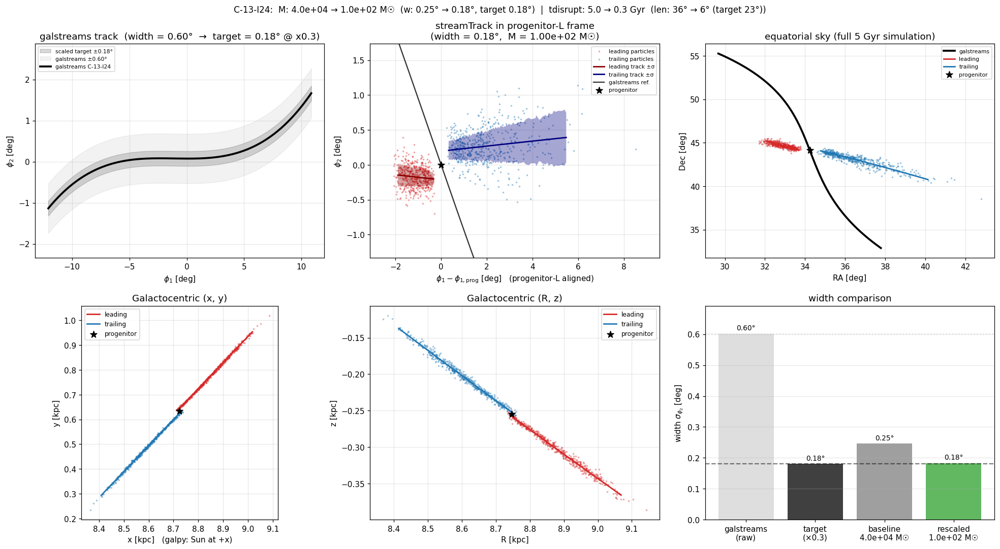

In [34]:
show_stream('C-13-I24')

## Stream 32: `New-25-I24`

New-25-I24:  galstreams width = 1.036°, target = 0.311°, baseline w = 0.792°, rescaled w = 0.254°, M = 1.00e+02 M_sun


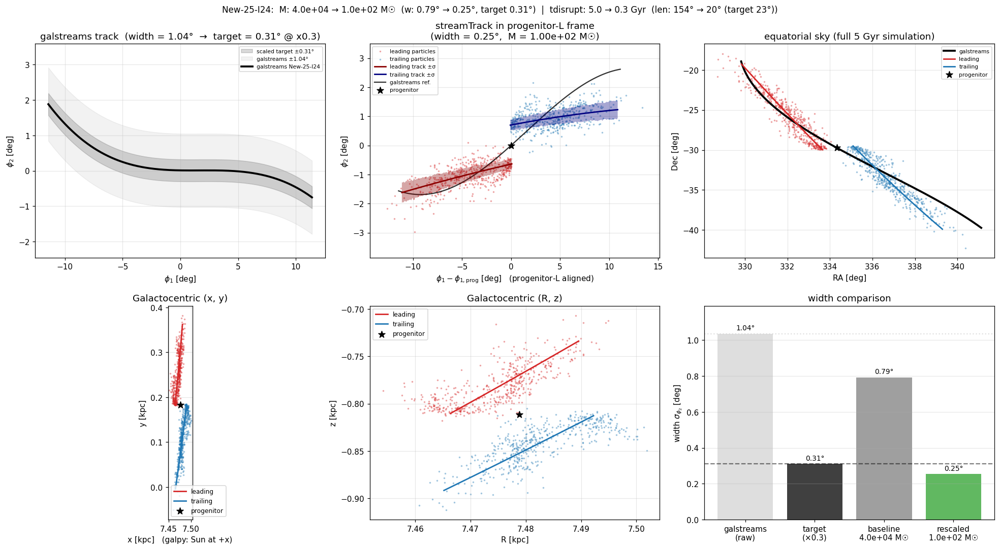

In [35]:
show_stream('New-25-I24')

## Stream 33: `Gaia-9-I21`

Gaia-9-I21:  galstreams width = 1.186°, target = 0.356°, baseline w = 2.306°, rescaled w = 0.199°, M = 4.36e+02 M_sun


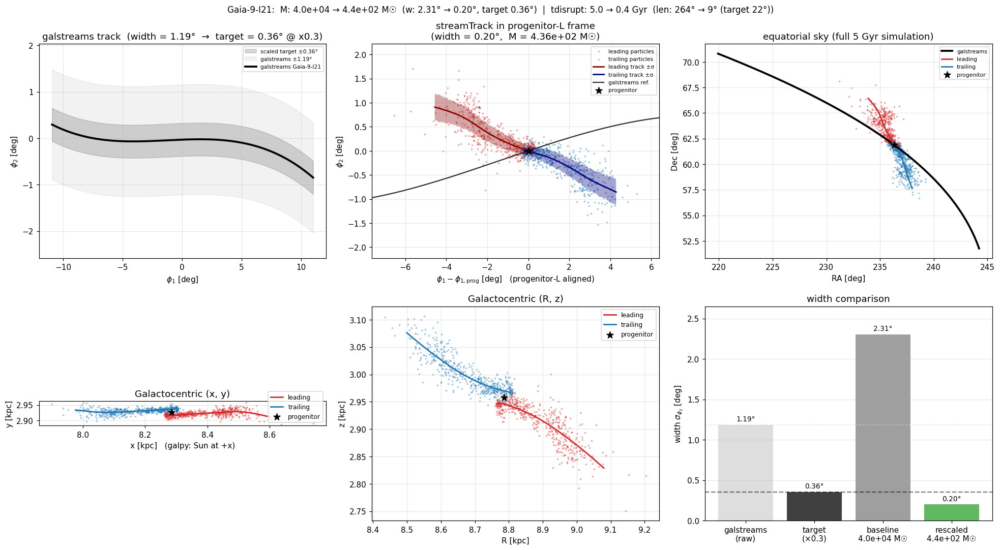

In [36]:
show_stream('Gaia-9-I21')

## Stream 34: `Gaia-11-I21`

Gaia-11-I21:  galstreams width = 0.264°, target = 0.079°, baseline w = 0.444°, rescaled w = 0.026°, M = 1.00e+02 M_sun


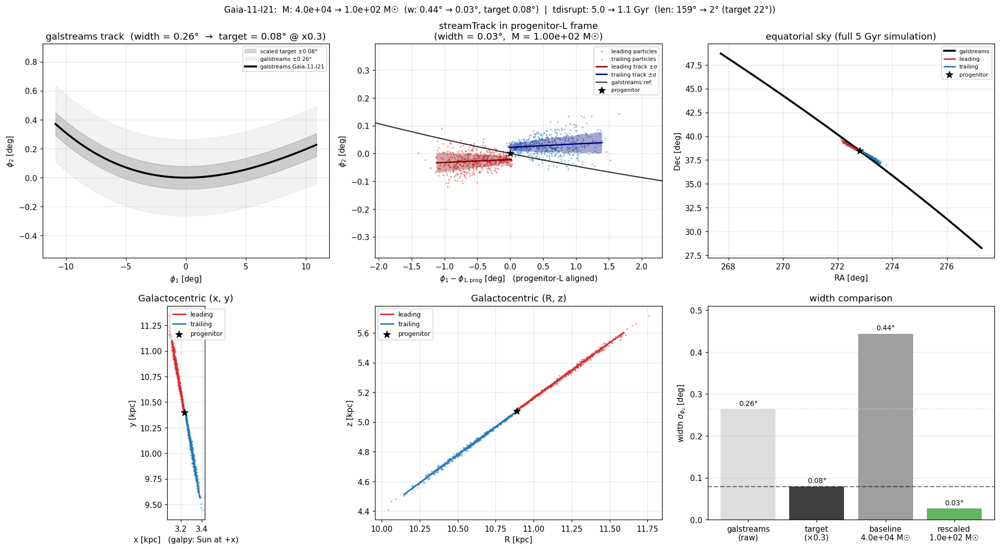

In [37]:
show_stream('Gaia-11-I21')

## Stream 35: `Gaia-8-I21`

Gaia-8-I21:  galstreams width = 0.640°, target = 0.192°, baseline w = 0.387°, rescaled w = 0.158°, M = 4.85e+04 M_sun


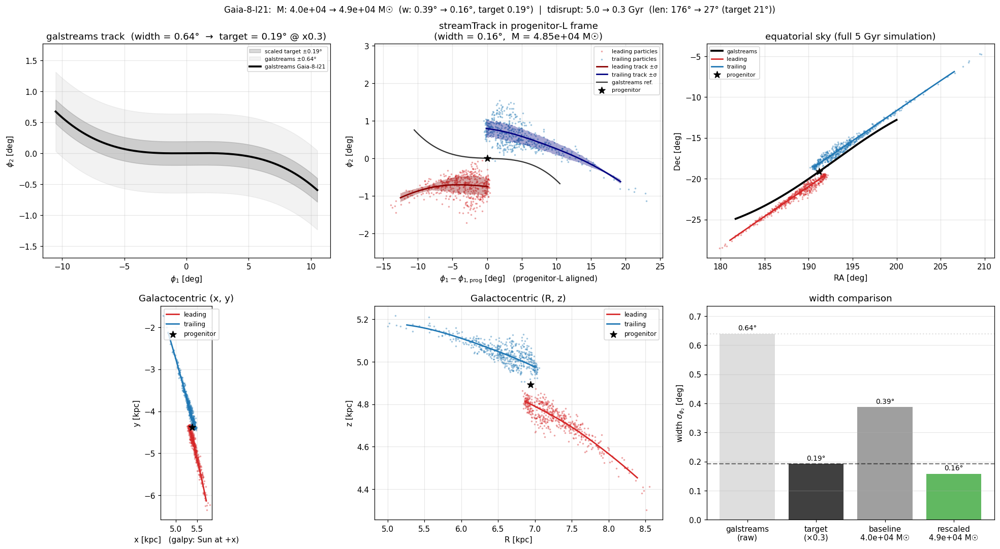

In [38]:
show_stream('Gaia-8-I21')

## Stream 36: `M92-I21`

M92-I21:  galstreams width = 1.409°, target = 0.423°, baseline w = 0.585°, rescaled w = 0.249°, M = 9.69e+03 M_sun


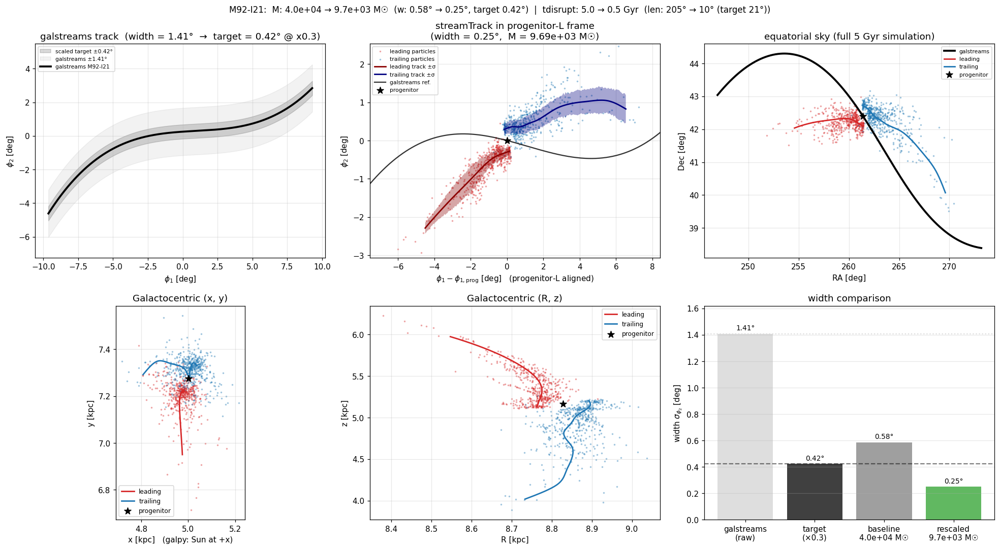

In [39]:
show_stream('M92-I21')

## Stream 37: `Gaia-6-I21`

Gaia-6-I21:  galstreams width = 0.096°, target = 0.029°, baseline w = 0.221°, rescaled w = 0.033°, M = 2.18e+02 M_sun


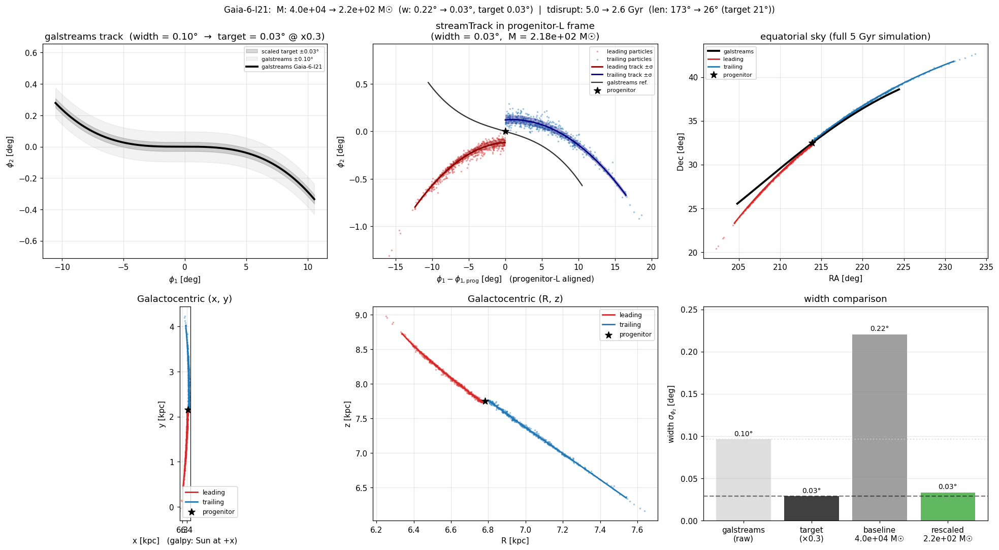

In [40]:
show_stream('Gaia-6-I21')

## Stream 38: `Kwando-I21`

Kwando-I21:  galstreams width = 0.967°, target = 0.290°, baseline w = 0.581°, rescaled w = 0.076°, M = 2.35e+03 M_sun


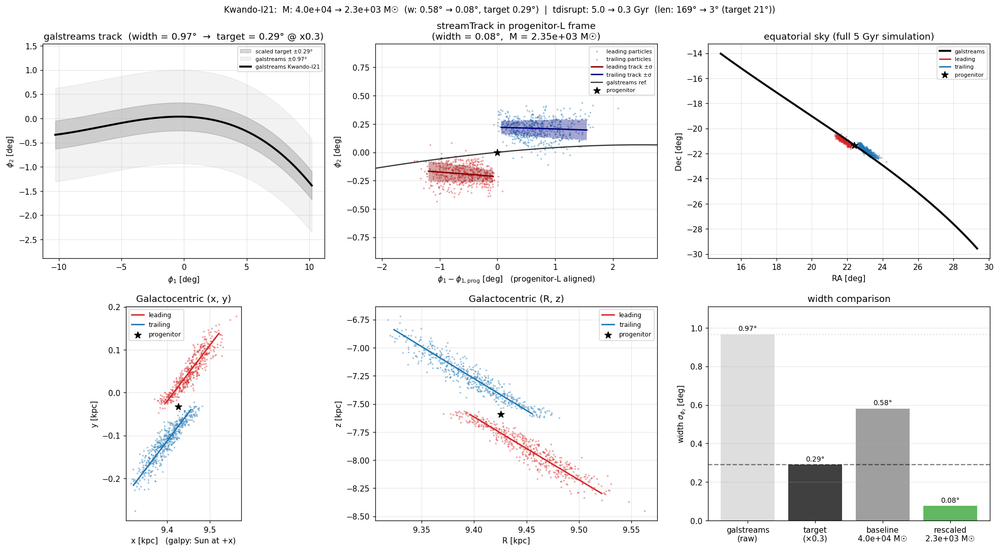

In [41]:
show_stream('Kwando-I21')

## Stream 39: `C-23-I24`

C-23-I24:  galstreams width = 0.310°, target = 0.093°, baseline w = 0.212°, rescaled w = 0.178°, M = 1.00e+02 M_sun


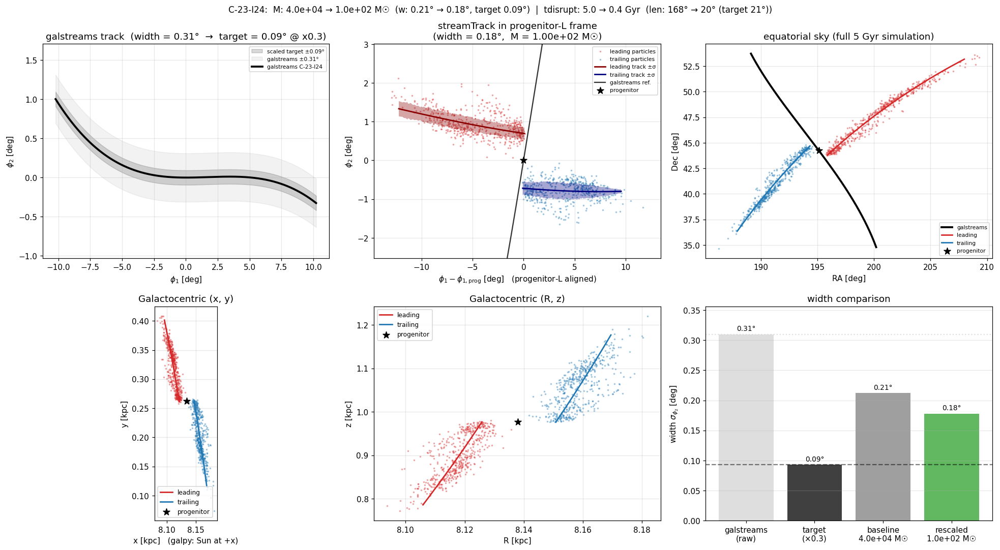

In [42]:
show_stream('C-23-I24')

## Stream 40: `Gunnthra-I21`

Gunnthra-I21:  galstreams width = 1.597°, target = 0.479°, baseline w = 1.149°, rescaled w = 0.477°, M = 1.48e+04 M_sun


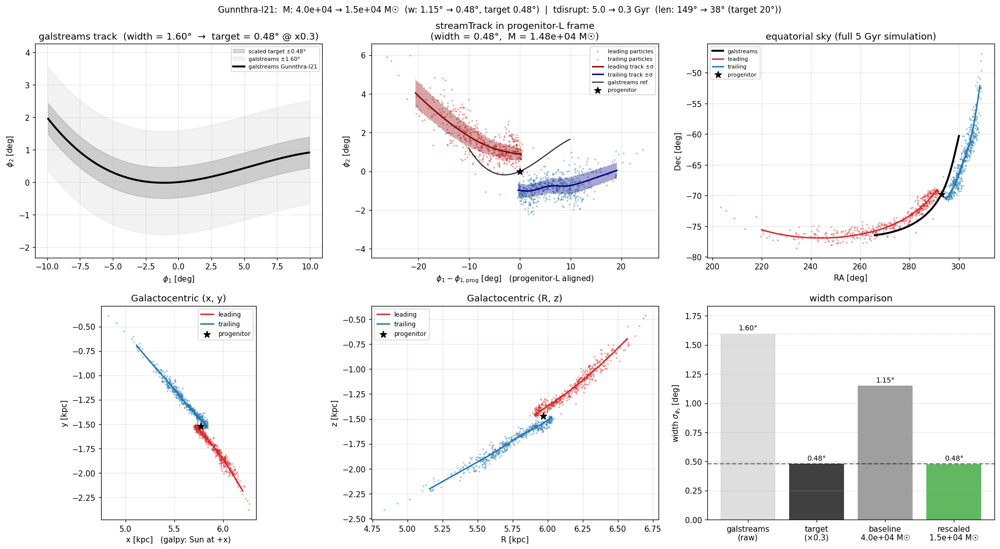

In [43]:
show_stream('Gunnthra-I21')

## Stream 41: `New-15-I24`

New-15-I24:  galstreams width = 3.147°, target = 0.944°, baseline w = 0.238°, rescaled w = 1.567°, M = 9.05e+04 M_sun


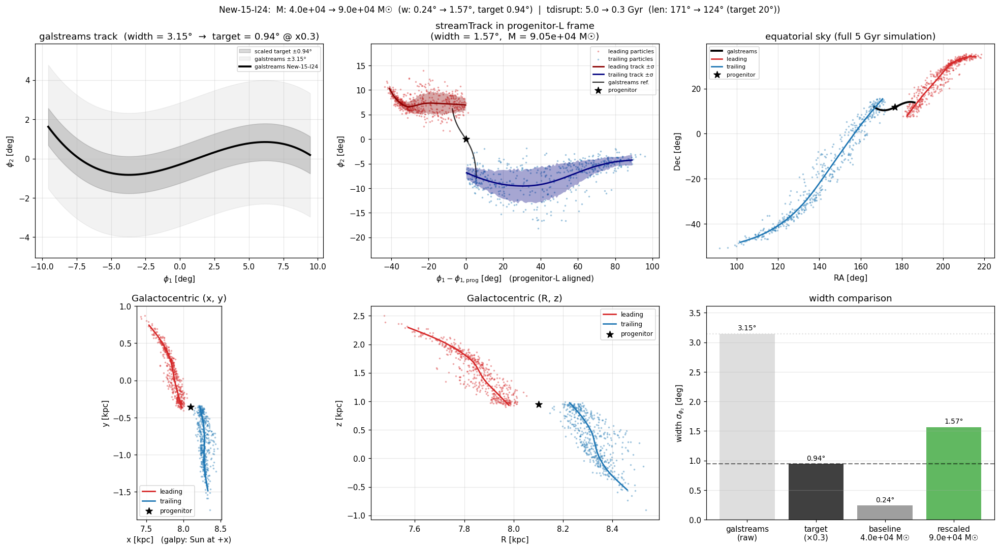

In [44]:
show_stream('New-15-I24')

## Stream 42: `NGC6397-I21`

NGC6397-I21:  galstreams width = 0.472°, target = 0.142°, baseline w = 2.077°, rescaled w = 0.272°, M = 1.00e+02 M_sun


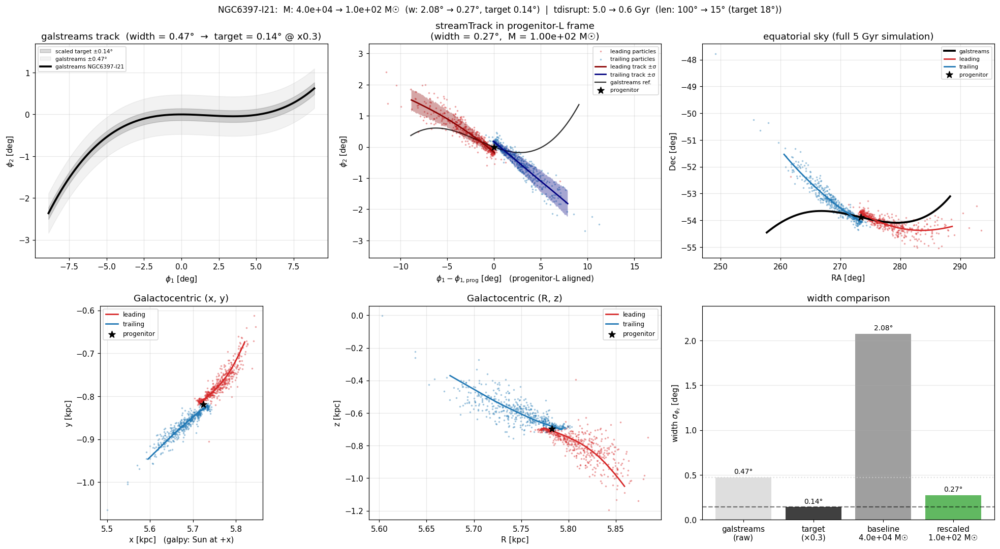

In [45]:
show_stream('NGC6397-I21')

## Stream 43: `NGC1261-I21`

NGC1261-I21:  galstreams width = 0.960°, target = 0.288°, baseline w = 0.473°, rescaled w = 0.191°, M = 1.36e+04 M_sun


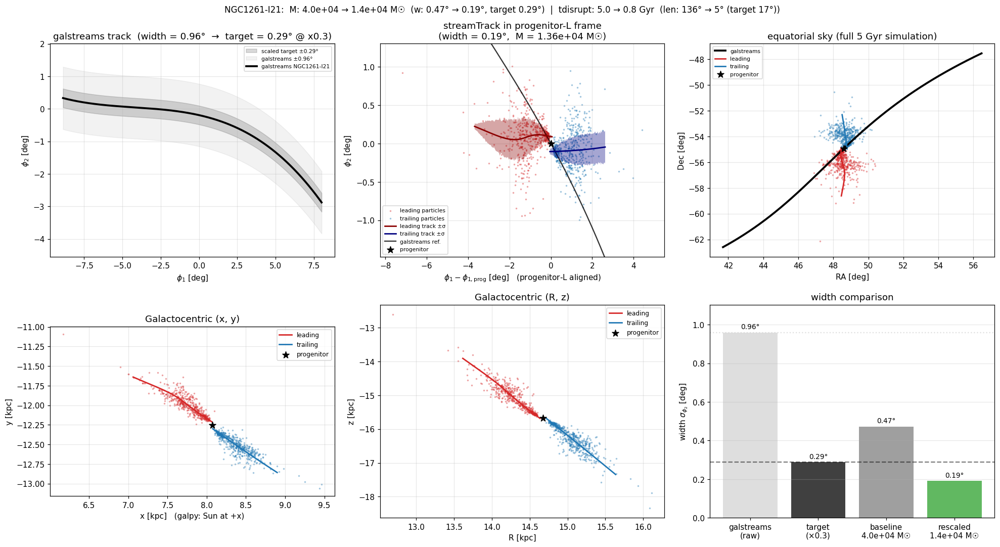

In [46]:
show_stream('NGC1261-I21')

## Stream 44: `Kshir-I21`

Kshir-I21:  galstreams width = 0.226°, target = 0.068°, baseline w = 0.174°, rescaled w = 0.067°, M = 3.15e+03 M_sun


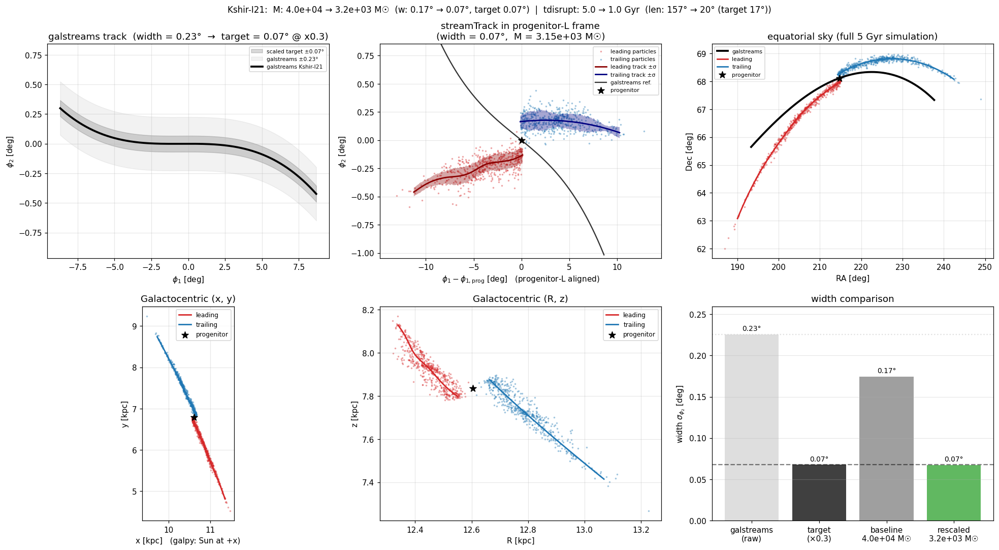

In [47]:
show_stream('Kshir-I21')

## Stream 45: `New-4-I24`

New-4-I24:  galstreams width = 0.152°, target = 0.046°, baseline w = 0.575°, rescaled w = 0.279°, M = 1.00e+02 M_sun


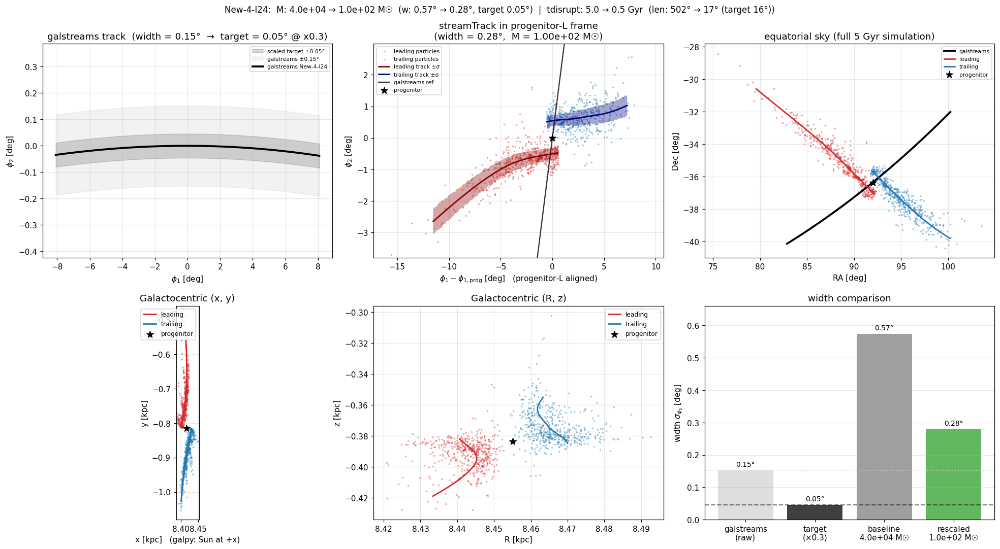

In [48]:
show_stream('New-4-I24')

## Stream 46: `C-10-I24`

C-10-I24:  galstreams width = 0.527°, target = 0.158°, baseline w = 0.598°, rescaled w = 0.158°, M = 2.07e+02 M_sun


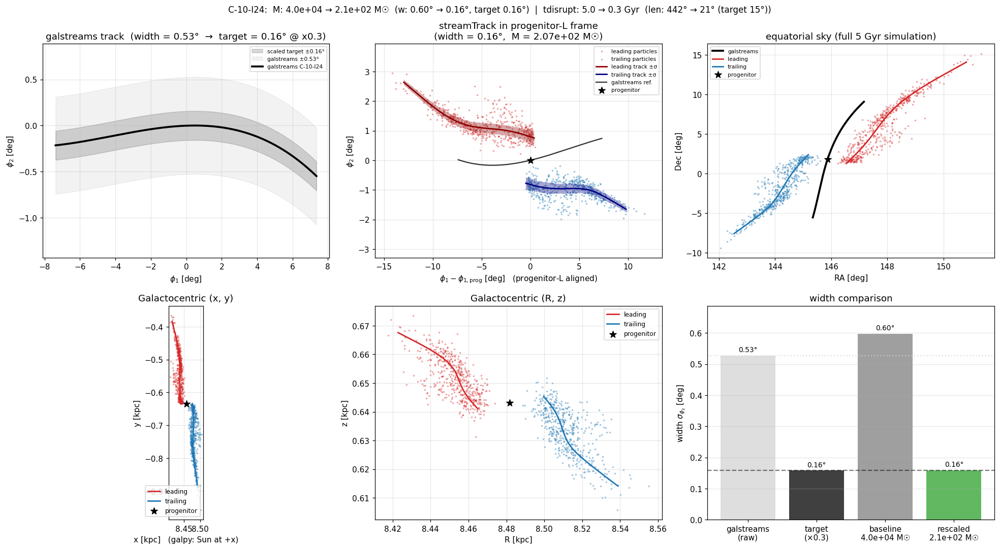

In [49]:
show_stream('C-10-I24')

## Stream 47: `Gaia-2-I21`

Gaia-2-I21:  galstreams width = 0.227°, target = 0.068°, baseline w = 0.636°, rescaled w = 0.064°, M = 1.00e+02 M_sun


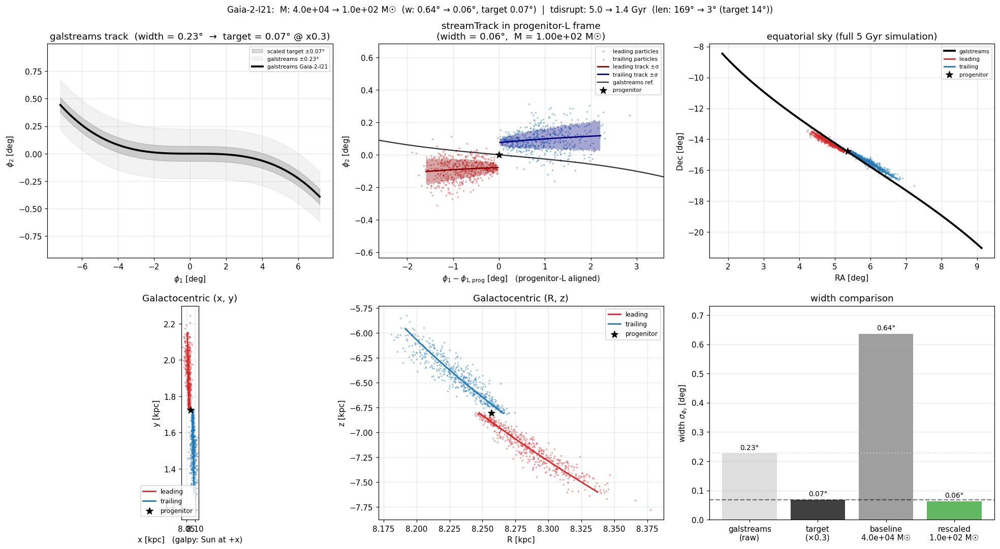

In [50]:
show_stream('Gaia-2-I21')

## Stream 48: `C-4-I21`

C-4-I21:  galstreams width = 0.548°, target = 0.164°, baseline w = 0.495°, rescaled w = 0.115°, M = 2.29e+02 M_sun


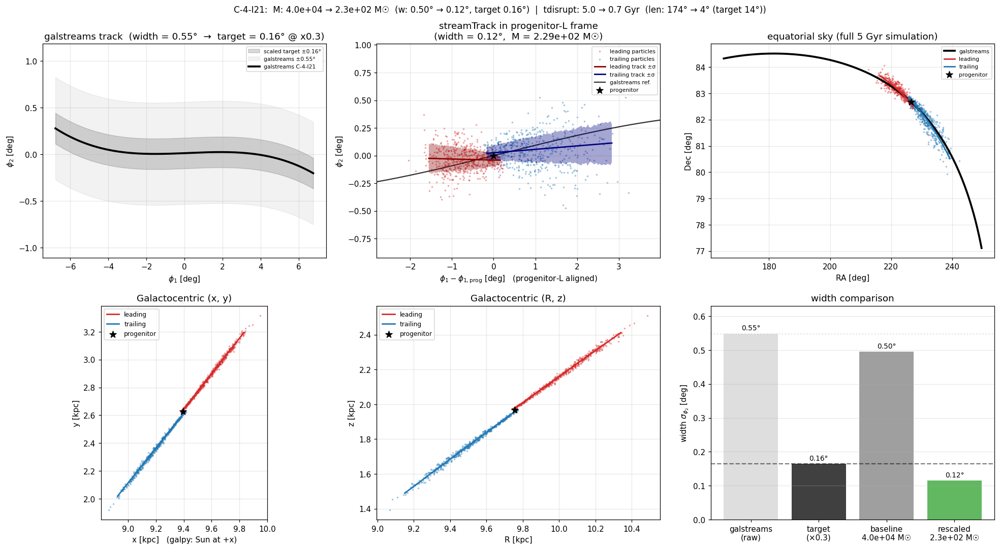

In [51]:
show_stream('C-4-I21')

## Stream 49: `Aquarius-W11`

Aquarius-W11:  galstreams width = 3.777°, target = 1.133°, baseline w = 0.319°, rescaled w = 1.145°, M = 8.01e+05 M_sun


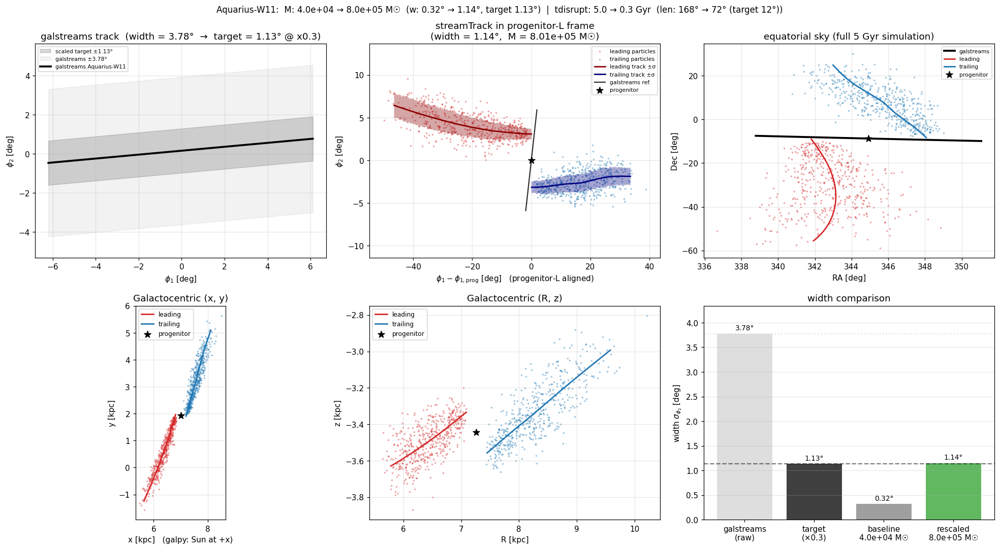

In [52]:
show_stream('Aquarius-W11')

## Stream 50: `New-27-I24`

New-27-I24:  galstreams width = 0.407°, target = 0.122°, baseline w = 0.436°, rescaled w = 0.203°, M = 1.00e+02 M_sun


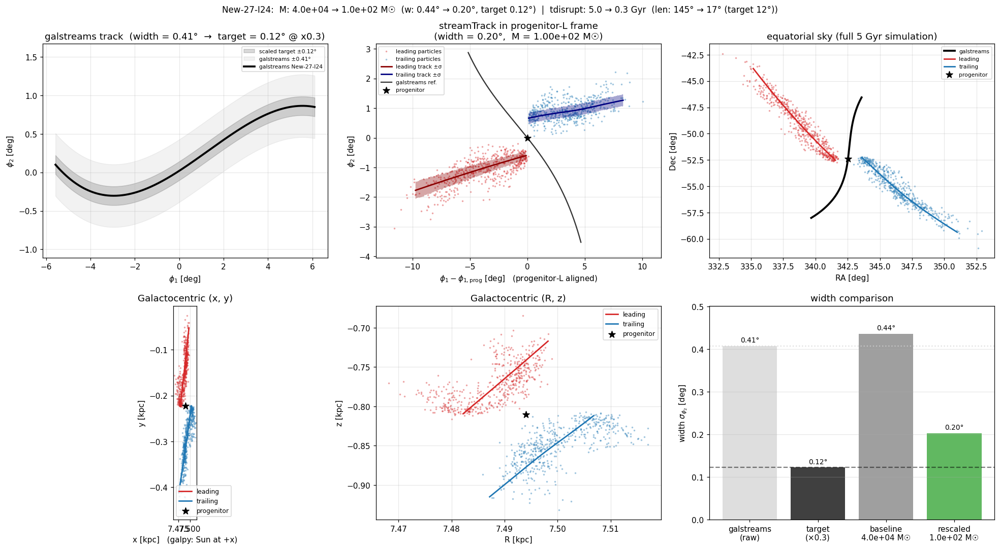

In [53]:
show_stream('New-27-I24')

## Stream 51: `New-22-I24`

New-22-I24:  galstreams width = 0.375°, target = 0.113°, baseline w = 1.178°, rescaled w = 0.134°, M = 1.00e+02 M_sun


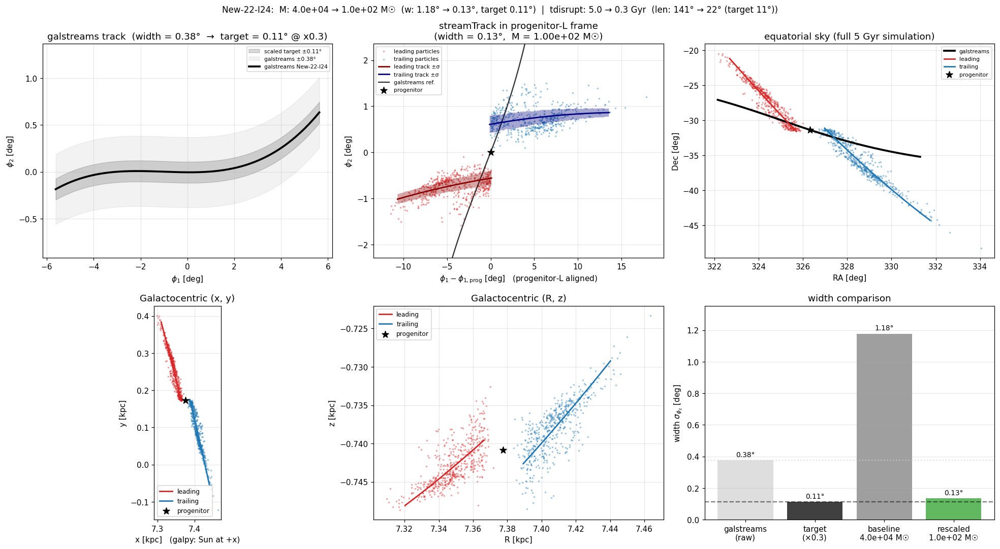

In [54]:
show_stream('New-22-I24')

## Stream 52: `NGC1261b-I24`

NGC1261b-I24:  galstreams width = 0.665°, target = 0.200°, baseline w = 0.000°, rescaled w = 0.000°, M = 1.00e+10 M_sun


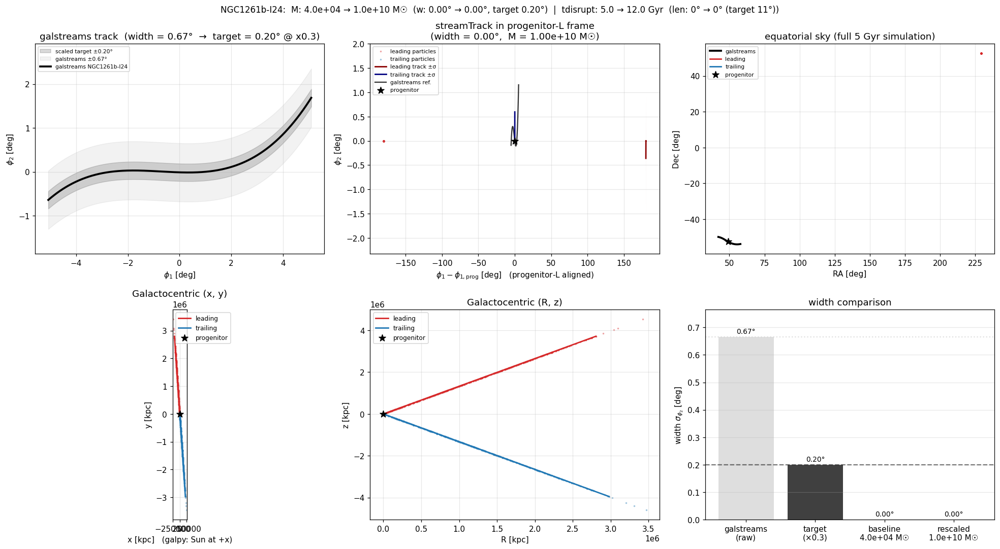

In [55]:
show_stream('NGC1261b-I24')

## Stream 53: `New-14-I24`

New-14-I24:  galstreams width = 0.757°, target = 0.227°, baseline w = 1.747°, rescaled w = 0.396°, M = 1.00e+02 M_sun


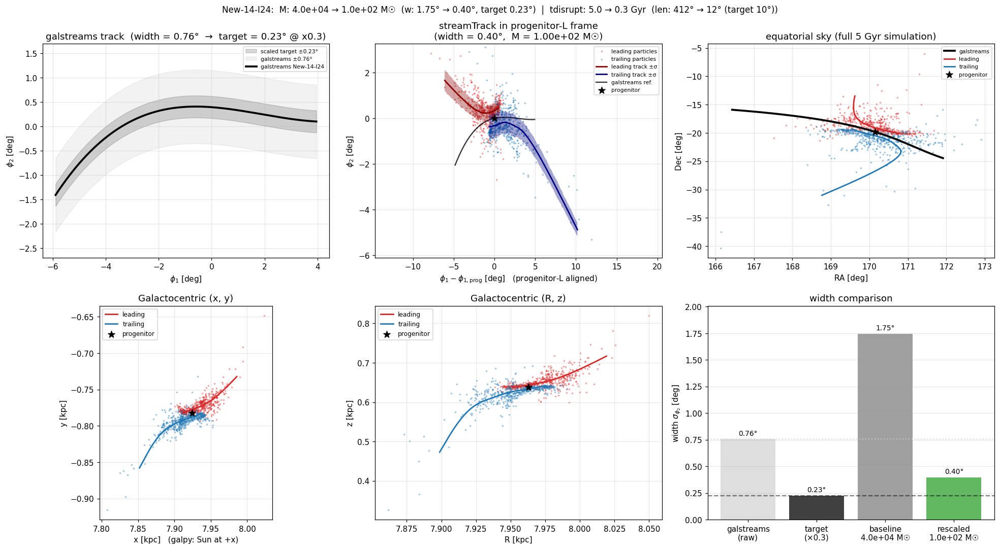

In [56]:
show_stream('New-14-I24')

## Stream 54: `C-8-I21`

C-8-I21:  galstreams width = 0.296°, target = 0.089°, baseline w = 0.672°, rescaled w = 0.099°, M = 1.00e+02 M_sun


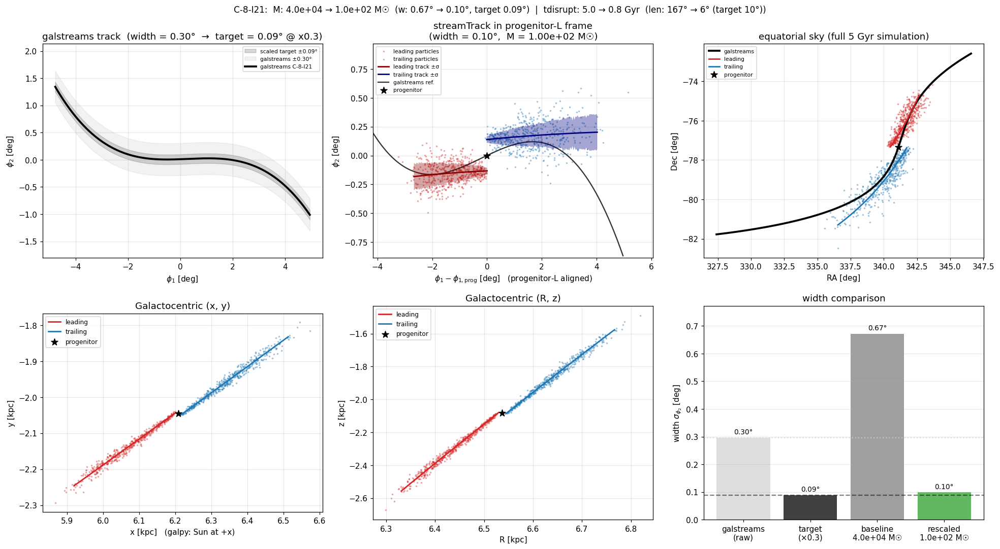

In [57]:
show_stream('C-8-I21')

## Stream 55: `C-22-I24`

C-22-I24:  galstreams width = 0.360°, target = 0.108°, baseline w = 0.315°, rescaled w = 0.181°, M = 1.00e+02 M_sun


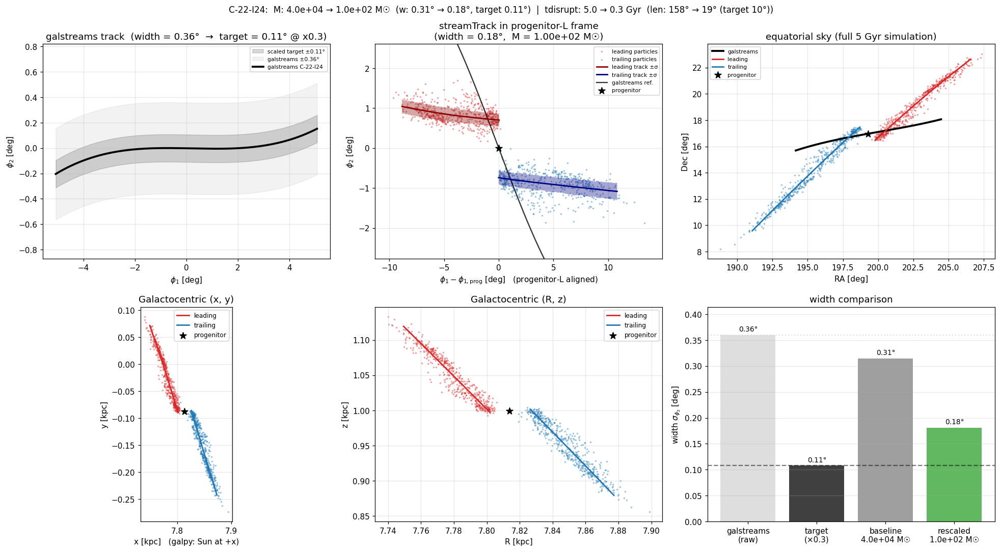

In [58]:
show_stream('C-22-I24')

## Stream 56: `New-20-I24`

New-20-I24:  galstreams width = 1.862°, target = 0.559°, baseline w = 0.934°, rescaled w = 0.557°, M = 3.06e+03 M_sun


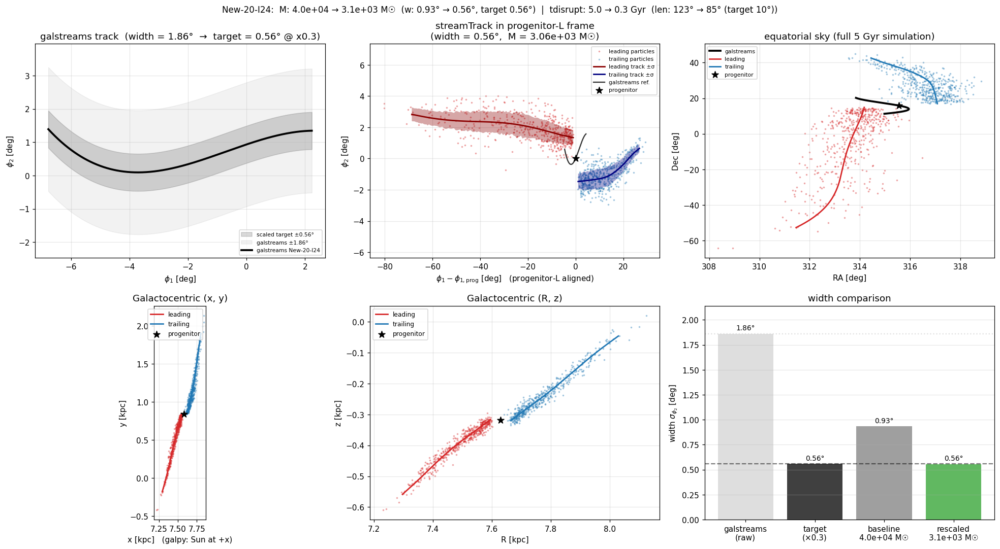

In [59]:
show_stream('New-20-I24')

## Stream 57: `New-9-I24`

New-9-I24:  galstreams width = 0.768°, target = 0.231°, baseline w = 0.255°, rescaled w = 0.232°, M = 2.44e+02 M_sun


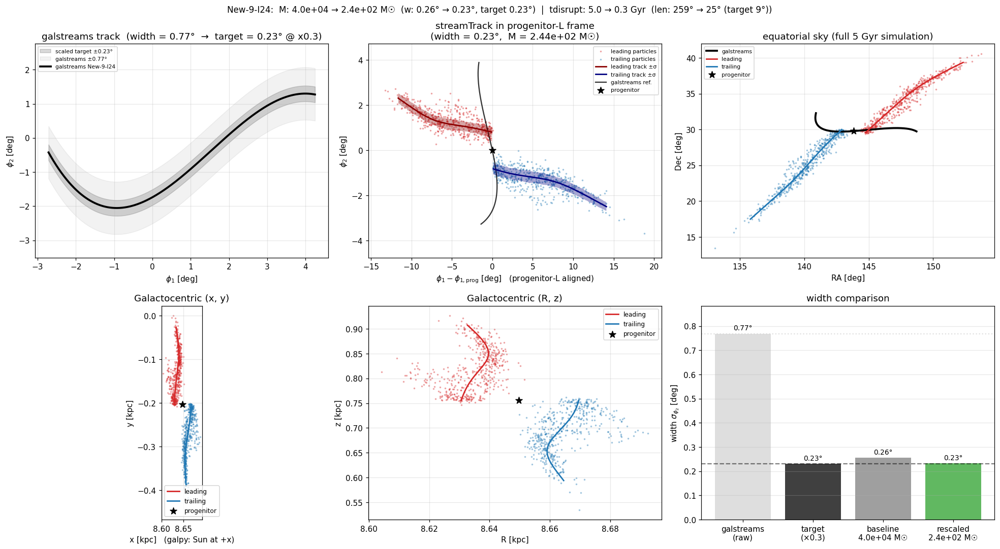

In [60]:
show_stream('New-9-I24')

## Stream 58: `New-26-I24`

New-26-I24:  galstreams width = 0.394°, target = 0.118°, baseline w = 0.117°, rescaled w = 0.081°, M = 2.32e+05 M_sun


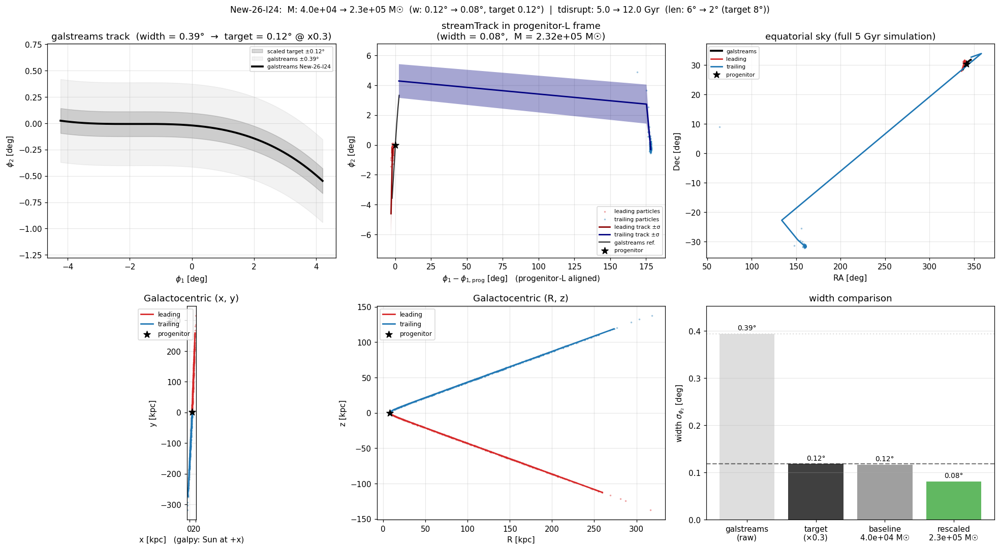

In [61]:
show_stream('New-26-I24')

## Stream 59: `New-11-I24`

New-11-I24:  galstreams width = 0.318°, target = 0.096°, baseline w = 1.328°, rescaled w = 0.253°, M = 1.00e+02 M_sun


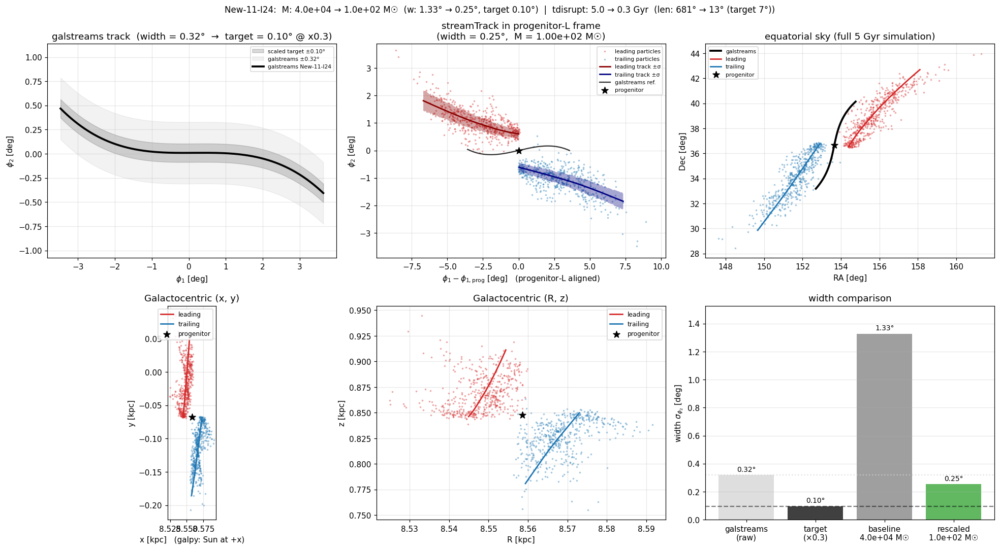

In [62]:
show_stream('New-11-I24')

## Stream 60: `C-5-I21`

C-5-I21:  galstreams width = 0.106°, target = 0.032°, baseline w = 1.752°, rescaled w = 0.136°, M = 1.00e+02 M_sun


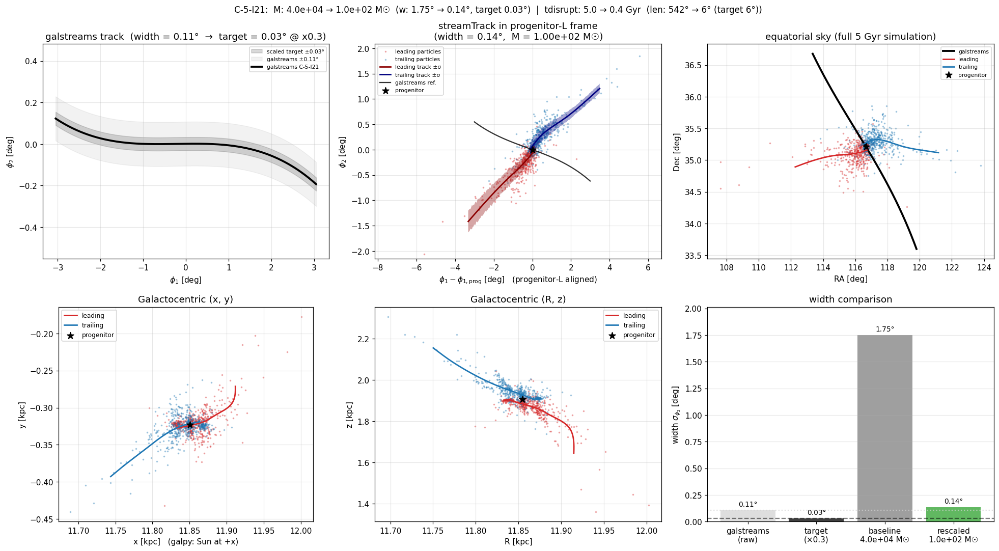

In [63]:
show_stream('C-5-I21')

## Stream 61: `Hydrus-I24`

Hydrus-I24:  galstreams width = 0.203°, target = 0.061°, baseline w = 0.000°, rescaled w = 0.000°, M = 1.00e+10 M_sun


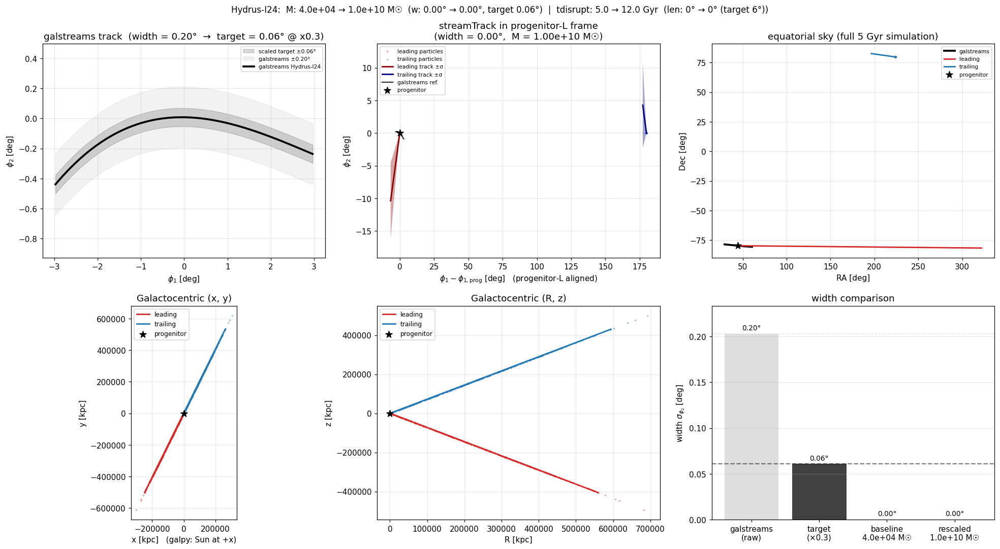

In [64]:
show_stream('Hydrus-I24')

## Stream 62: `New-19-I24`

New-19-I24:  galstreams width = 1.260°, target = 0.378°, baseline w = 0.496°, rescaled w = 0.387°, M = 6.63e+02 M_sun


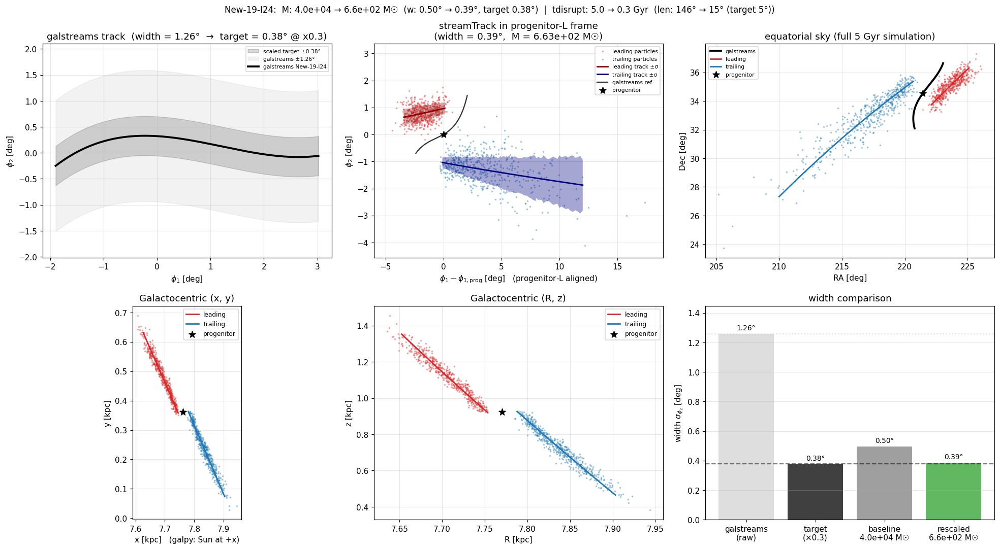

In [65]:
show_stream('New-19-I24')

## Stream 63: `New-24-I24`

New-24-I24:  galstreams width = 0.896°, target = 0.269°, baseline w = 1.253°, rescaled w = 0.268°, M = 1.11e+02 M_sun


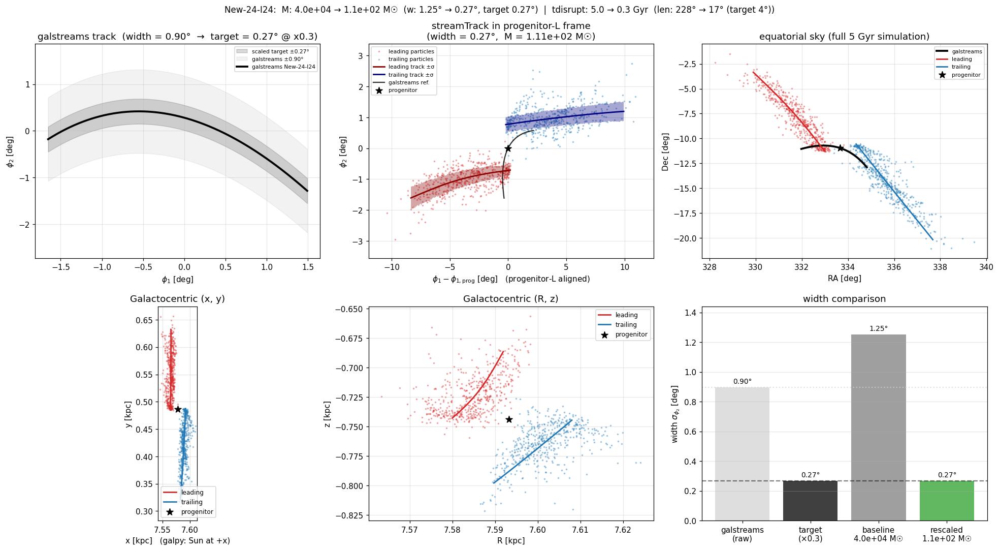

In [66]:
show_stream('New-24-I24')